# DSCI 552 — Homework 4

**Name:** Yuanda SHI  
**USC ID:** 6635-4638-05

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd

from IPython.display import display

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd()
DATA_BASE = PROJECT_ROOT / "data" / "AReM"

print("Project directory:", PROJECT_ROOT)
print("Data directory:", DATA_BASE)
print("Data directory exists:", DATA_BASE.exists())

Project directory: /Users/sydsam/Desktop/DSCI552/HW3
Data directory: /Users/sydsam/Desktop/DSCI552/HW3/data/AReM
Data directory exists: True


## 1. Time Series Classification Part 1: Feature Creation/Extraction
### 1(a) AReM Data Set

The AReM dataset contains seven activity folders. Each instance contains six time series:

1. `avg_rss12`
2. `var_rss12`
3. `avg_rss13`
4. `var_rss13`
5. `avg_rss23`
6. `var_rss23`

Each time series contains 480 consecutive observations.

In [2]:
ACTIVITIES = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

candidate_directories = [DATA_BASE]

candidate_directories.extend(
    path for path in DATA_BASE.rglob("*")
    if path.is_dir()
)

matching_roots = [
    path
    for path in candidate_directories
    if all((path / activity).is_dir()
           for activity in ACTIVITIES)
]

assert len(matching_roots) > 0, (
    "Could not find the seven AReM activity folders "
    "under data/AReM."
)

DATA_ROOT = matching_roots[0]

print("AReM root:", DATA_ROOT)

for activity in ACTIVITIES:
    files = list((DATA_ROOT / activity).glob("dataset*.csv"))
    print(f"{activity}: {len(files)} files")

AReM root: /Users/sydsam/Desktop/DSCI552/HW3/data/AReM
bending1: 7 files
bending2: 6 files
cycling: 15 files
lying: 15 files
sitting: 15 files
standing: 15 files
walking: 15 files


In [3]:
RAW_COLUMNS = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]


def get_dataset_id(file_path):
    """
    Extract dataset number from filenames such as:
    dataset1.csv, dataset2.csv, ...
    """
    match = re.search(
        r"dataset(\d+)",
        file_path.stem,
        re.IGNORECASE
    )

    if match is None:
        raise ValueError(
            f"Cannot determine dataset number from: {file_path}"
        )

    return int(match.group(1))


def read_arem_csv(file_path, activity, dataset_id):
    """
    Read and lightly clean one AReM data file.

    Cleaning steps:
    1. Ignore comments and blank lines.
    2. Handle comma-separated files.
    3. Handle the whitespace-formatted bending2/dataset4.csv.
    4. Remove accidental trailing commas.
    5. Convert all columns to numeric.
    6. If exactly one 250-ms timestamp is missing from a
       479-row instance, reconstruct it using linear interpolation.
    7. Require exactly 480 observations after cleaning.
    """

    # ------------------------------------------------------------
    # Special case:
    # bending2/dataset4.csv uses whitespace rather than commas
    # ------------------------------------------------------------
    if activity == "bending2" and dataset_id == 4:

        frame = pd.read_csv(
            file_path,
            comment="#",
            header=None,
            names=RAW_COLUMNS,
            sep=r"\s+",
            engine="python"
        )

    # ------------------------------------------------------------
    # Standard comma-separated AReM files
    # ------------------------------------------------------------
    else:

        cleaned_rows = []

        with open(
            file_path,
            "r",
            encoding="utf-8",
            errors="replace"
        ) as file:

            for line_number, line in enumerate(
                file,
                start=1
            ):
                line = line.strip()

                # Ignore comments and blank lines
                if (
                    not line
                    or line.startswith("#")
                ):
                    continue

                # Remove accidental trailing commas
                line = line.rstrip(",")

                values = [
                    value.strip()
                    for value in line.split(",")
                ]

                if len(values) != 7:
                    raise ValueError(
                        f"\nFORMAT ERROR\n"
                        f"Activity: {activity}\n"
                        f"Dataset: {dataset_id}\n"
                        f"File: {file_path}\n"
                        f"Line: {line_number}\n"
                        f"Fields found: {len(values)}\n"
                        f"Expected: 7\n"
                        f"Content: {line}"
                    )

                cleaned_rows.append(values)

        frame = pd.DataFrame(
            cleaned_rows,
            columns=RAW_COLUMNS
        )

    # ------------------------------------------------------------
    # Convert all fields to numeric
    # ------------------------------------------------------------
    for column in RAW_COLUMNS:
        frame[column] = pd.to_numeric(
            frame[column],
            errors="coerce"
        )

    # Check for missing / non-numeric values
    if frame.isna().any().any():

        bad_rows = frame[
            frame.isna().any(axis=1)
        ]

        raise ValueError(
            f"\nNON-NUMERIC OR MISSING VALUES\n"
            f"Activity: {activity}\n"
            f"Dataset: {dataset_id}\n"
            f"File: {file_path}\n\n"
            f"{bad_rows}"
        )

    # ------------------------------------------------------------
    # Sort by timestamp
    # ------------------------------------------------------------
    frame = (
        frame
        .sort_values("time")
        .reset_index(drop=True)
    )

    # ------------------------------------------------------------
    # Repair exactly one missing 250-ms observation
    # ------------------------------------------------------------
    if len(frame) == 479:

        observed_times = frame[
            "time"
        ].to_numpy()

        start_time = observed_times.min()

        expected_times = np.arange(
            start_time,
            start_time + 480 * 250,
            250
        )

        missing_times = np.setdiff1d(
            expected_times,
            observed_times
        )

        if len(missing_times) == 1:

            missing_time = missing_times[0]

            print(
                f"Cleaning {activity}/dataset{dataset_id}: "
                f"interpolating missing timestamp "
                f"{missing_time}."
            )

            missing_row = pd.DataFrame({
                "time": [missing_time],
                "avg_rss12": [np.nan],
                "var_rss12": [np.nan],
                "avg_rss13": [np.nan],
                "var_rss13": [np.nan],
                "avg_rss23": [np.nan],
                "var_rss23": [np.nan]
            })

            frame = pd.concat(
                [
                    frame,
                    missing_row
                ],
                ignore_index=True
            )

            frame = (
                frame
                .sort_values("time")
                .reset_index(drop=True)
            )

            signal_columns = RAW_COLUMNS[1:]

            frame[signal_columns] = (
                frame[signal_columns]
                .interpolate(
                    method="linear",
                    limit_direction="both"
                )
            )

        else:

            raise ValueError(
                f"\nUNEXPECTED 479-ROW FILE\n"
                f"Activity: {activity}\n"
                f"Dataset: {dataset_id}\n"
                f"File: {file_path}\n"
                f"Missing timestamps found: "
                f"{missing_times}"
            )

    # ------------------------------------------------------------
    # Final validation for each instance
    # ------------------------------------------------------------
    if len(frame) != 480:

        raise ValueError(
            f"\nFILE LENGTH ERROR\n"
            f"Activity: {activity}\n"
            f"Dataset: {dataset_id}\n"
            f"File: {file_path}\n"
            f"Rows after cleaning: {len(frame)}\n"
            f"Expected: 480"
        )

    # Verify timestamps are evenly spaced by 250 ms
    time_differences = (
        frame["time"]
        .diff()
        .dropna()
        .to_numpy()
    )

    if not np.all(
        time_differences == 250
    ):
        raise ValueError(
            f"\nTIMESTAMP ERROR\n"
            f"Activity: {activity}\n"
            f"Dataset: {dataset_id}\n"
            f"File: {file_path}\n"
            f"Not all time intervals are 250 ms."
        )

    return frame


# ================================================================
# Read all AReM instances
# ================================================================

raw_instances = {}
validation_records = []

for activity in ACTIVITIES:

    activity_files = sorted(
        (DATA_ROOT / activity)
        .glob("dataset*.csv"),
        key=get_dataset_id
    )

    for file_path in activity_files:

        dataset_id = get_dataset_id(
            file_path
        )

        frame = read_arem_csv(
            file_path,
            activity,
            dataset_id
        )

        key = (
            activity,
            dataset_id
        )

        raw_instances[key] = frame

        validation_records.append({
            "activity": activity,
            "dataset_id": dataset_id,
            "rows": frame.shape[0],
            "columns": frame.shape[1],
            "file": file_path.name
        })


# ================================================================
# Validation summary
# ================================================================

validation_df = pd.DataFrame(
    validation_records
)

print(
    "\nNumber of instances:",
    len(raw_instances)
)

print(
    "All instances have 480 rows:",
    (validation_df["rows"] == 480).all()
)

print(
    "All instances have 7 raw columns:",
    (validation_df["columns"] == 7).all()
)

print(
    "Total number of time-step records:",
    validation_df["rows"].sum()
)

print(
    "Expected total number of records:",
    88 * 480
)

display(
    validation_df.groupby("activity")
    .agg(
        instances=("dataset_id", "count"),
        min_rows=("rows", "min"),
        max_rows=("rows", "max")
    )
)

Cleaning sitting/dataset8: interpolating missing timestamp 13500.

Number of instances: 88
All instances have 480 rows: True
All instances have 7 raw columns: True
Total number of time-step records: 42240
Expected total number of records: 42240


,instances,min_rows,max_rows
activity,,,
bending1,7,480,480
bending2,6,480,480
cycling,15,480,480
lying,15,480,480
sitting,15,480,480
standing,15,480,480
walking,15,480,480


### 1(b) Train/Test Split

Use:

- datasets 1 and 2 in `bending1` and `bending2` as test data;
- datasets 1, 2, and 3 in all other activity folders as test data;
- all remaining instances as training data.

In [4]:
split_records = []

for (activity, dataset_id), frame in raw_instances.items():
    
    if activity in ["bending1", "bending2"]:
        is_test = dataset_id in [1, 2]
    else:
        is_test = dataset_id in [1, 2, 3]
    
    split_records.append({
        "activity": activity,
        "dataset_id": dataset_id,
        "instance": f"{activity}_dataset{dataset_id}",
        "split": "test" if is_test else "train"
    })


split_df = (
    pd.DataFrame(split_records)
    .sort_values(
        ["activity", "dataset_id"]
    )
    .reset_index(drop=True)
)

display(split_df)

print("\nSplit counts:")
print(split_df["split"].value_counts())

print("\nCounts by activity:")
display(
    pd.crosstab(
        split_df["activity"],
        split_df["split"]
    )
)

,activity,dataset_id,instance,split
0,bending1,1,bending1_dataset1,test
1,bending1,2,bending1_dataset2,test
2,bending1,3,bending1_dataset3,train
3,bending1,4,bending1_dataset4,train
4,bending1,5,bending1_dataset5,train
...,...,...,...,...
83,walking,11,walking_dataset11,train
84,walking,12,walking_dataset12,train
85,walking,13,walking_dataset13,train
86,walking,14,walking_dataset14,train



Split counts:
split
train    69
test     19
Name: count, dtype: int64

Counts by activity:


split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


**Train/Test Split**

The train-test split was created strictly according to the homework instructions rather than by random sampling.

The dataset identifiers within each activity folder determine whether an instance belongs to the training or test set. This preserves the exact experimental design specified in the assignment.

### 1(c) Feature Extraction

#### 1(c)i Common Time-Domain Features

Commonly used time-domain features for time-series classification include:

**Measures of location**
- Minimum
- Maximum
- Mean
- Median
- Quantiles / quartiles

**Measures of dispersion**
- Variance
- Standard deviation
- Range
- Interquartile range (IQR)
- Median absolute deviation

**Measures of distribution shape**
- Skewness
- Kurtosis

**Signal magnitude and energy**
- Root mean square (RMS)
- Signal energy
- Mean absolute value

**Temporal and change-related features**
- Mean absolute change
- Number of zero or mean crossings
- Number of peaks
- Trend/slope
- Autocorrelation

For this homework, the required features are:

- minimum
- maximum
- mean
- median
- standard deviation
- first quartile
- third quartile

#### 1(c)ii Extract the Required Time-Domain Features

For each of the six time series in every instance, extract:

1. minimum
2. maximum
3. mean
4. median
5. standard deviation
6. first quartile
7. third quartile

Therefore, each instance is represented by:

\[
6 \times 7 = 42
\]

time-domain features.

The features are used directly without normalization or standardization in this section.

In [5]:
TIME_SERIES_COLUMNS = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]


def extract_time_domain_features(frame):
    
    result = {}
    
    for series_number, column in enumerate(
        TIME_SERIES_COLUMNS,
        start=1
    ):
        series = frame[column]
        
        result[f"min{series_number}"] = (
            series.min()
        )
        
        result[f"max{series_number}"] = (
            series.max()
        )
        
        result[f"mean{series_number}"] = (
            series.mean()
        )
        
        result[f"median{series_number}"] = (
            series.median()
        )
        
        result[f"std{series_number}"] = (
            series.std(ddof=1)
        )
        
        result[f"1st_quart{series_number}"] = (
            series.quantile(0.25)
        )
        
        result[f"3rd_quart{series_number}"] = (
            series.quantile(0.75)
        )
    
    return result


feature_rows = []

for (activity, dataset_id), frame in raw_instances.items():
    
    split = split_df.loc[
        (split_df["activity"] == activity) &
        (split_df["dataset_id"] == dataset_id),
        "split"
    ].iloc[0]
    
    row = {
        "instance": f"{activity}_dataset{dataset_id}",
        "activity": activity,
        "dataset_id": dataset_id,
        "split": split
    }
    
    row.update(
        extract_time_domain_features(frame)
    )
    
    feature_rows.append(row)


feature_df = (
    pd.DataFrame(feature_rows)
    .sort_values(
        ["activity", "dataset_id"]
    )
    .reset_index(drop=True)
)

feature_df.head()

,instance,activity,dataset_id,split,min1,max1,mean1,median1,std1,1st_quart1,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,bending1_dataset1,bending1,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1_dataset2,bending1,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1_dataset3,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1_dataset4,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1_dataset5,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


In [6]:
feature_columns = [
    column
    for column in feature_df.columns
    if column not in [
        "instance",
        "activity",
        "dataset_id",
        "split"
    ]
]

print(
    "Number of instances:",
    feature_df.shape[0]
)

print(
    "Number of extracted features:",
    len(feature_columns)
)

print(
    "Missing feature values:",
    feature_df[feature_columns]
    .isna()
    .sum()
    .sum()
)

display(
    feature_df[
        ["instance"] + feature_columns
    ].head()
)

Number of instances: 88
Number of extracted features: 42
Missing feature values: 0


,instance,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,bending1_dataset1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1_dataset2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1_dataset3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1_dataset4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1_dataset5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


In [7]:
train_features = (
    feature_df[
        feature_df["split"] == "train"
    ]
    .reset_index(drop=True)
)

test_features = (
    feature_df[
        feature_df["split"] == "test"
    ]
    .reset_index(drop=True)
)

print(
    "Training instances:",
    len(train_features)
)

print(
    "Test instances:",
    len(test_features)
)

print(
    "Total:",
    len(train_features) + len(test_features)
)

Training instances: 69
Test instances: 19
Total: 88


**Feature Dataset**

Each of the 88 original time-series instances has been converted into a fixed-length vector containing 42 time-domain features.

The original temporal observations are therefore summarized into a tabular feature dataset suitable for subsequent classification tasks.

The training and test assignments were retained as metadata so that the same split can be reused in Homework 4.

#### 1(c)iii Standard Deviations and 90% Bootstrap Confidence Intervals

For each of the 42 extracted features, estimate its standard deviation across the 88 instances.

A nonparametric bootstrap is then used to construct a 90% confidence interval for each standard deviation.

The procedure is:

1. Resample the 88 instances with replacement.
2. Calculate the standard deviation of each feature in the bootstrap sample.
3. Repeat the process 2,000 times.
4. Use the 5th and 95th percentiles of the bootstrap distribution as the 90% confidence interval.

In [8]:
X_features = (
    feature_df[feature_columns]
    .to_numpy(dtype=float)
)

n_instances = X_features.shape[0]

# Point estimates of standard deviations
std_estimates = np.std(
    X_features,
    axis=0,
    ddof=1
)

# Bootstrap
N_BOOTSTRAPS = 2000

rng = np.random.default_rng(
    RANDOM_STATE
)

bootstrap_indices = rng.integers(
    low=0,
    high=n_instances,
    size=(N_BOOTSTRAPS, n_instances)
)

bootstrap_samples = (
    X_features[bootstrap_indices, :]
)

bootstrap_std = np.std(
    bootstrap_samples,
    axis=1,
    ddof=1
)

ci_lower = np.quantile(
    bootstrap_std,
    0.05,
    axis=0
)

ci_upper = np.quantile(
    bootstrap_std,
    0.95,
    axis=0
)

bootstrap_results = pd.DataFrame({
    "Feature": feature_columns,
    "Std Estimate": std_estimates,
    "90% CI Lower": ci_lower,
    "90% CI Upper": ci_upper
})

display(
    bootstrap_results.round(4)
)

,Feature,Std Estimate,90% CI Lower,90% CI Upper
0,min1,9.5700,8.2141,10.7750
1,max1,4.3944,3.3341,5.3163
2,mean1,5.3357,4.7090,5.8905
3,median1,5.4401,4.7684,6.0135
4,std1,1.7722,1.5623,1.9477
5,1st_quart1,6.1536,5.5572,6.6598
6,3rd_quart1,5.1389,4.3303,5.8597
7,min2,0.0000,0.0000,0.0000
8,max2,5.0627,4.6192,5.4059
9,mean2,1.5742,1.4005,1.7044


In [9]:
bootstrap_results_display = (
    bootstrap_results
    .set_index("Feature")
    .round(4)
)

display(
    bootstrap_results_display
)

,Std Estimate,90% CI Lower,90% CI Upper
Feature,,,
min1,9.5700,8.2141,10.7750
max1,4.3944,3.3341,5.3163
mean1,5.3357,4.7090,5.8905
median1,5.4401,4.7684,6.0135
std1,1.7722,1.5623,1.9477
1st_quart1,6.1536,5.5572,6.6598
3rd_quart1,5.1389,4.3303,5.8597
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6192,5.4059


### 1(c)iii Bootstrap Results — Interpretation

The estimated standard deviations and their 90% bootstrap confidence intervals show substantial differences in variability across the extracted time-domain features.

Several observations can be made from the results:

1. **Features from the first time series show relatively large variability.**

   In particular, `min1` has one of the largest estimated standard deviations:

   \[
   \text{SD}(\text{min1}) = 9.5700
   \]

   with a 90% bootstrap confidence interval of approximately

   \[
   [8.2141,\ 10.7750].
   \]

   Other features from the first time series also show relatively large variability, including:

   - `mean1`: SD = 5.3357, 90% CI = [4.7090, 5.8905]
   - `median1`: SD = 5.4401, 90% CI = [4.7684, 6.0135]
   - `1st_quart1`: SD = 6.1536, 90% CI = [5.5572, 6.6598]
   - `3rd_quart1`: SD = 5.1389, 90% CI = [4.3303, 5.8597]

2. **Features from the fifth time series are also highly variable.**

   For example:

   - `min5`: SD = 6.1240, 90% CI = [4.3766, 7.5031]
   - `max5`: SD = 5.7412, 90% CI = [4.7150, 6.5583]
   - `mean5`: SD = 5.6756, 90% CI = [4.4337, 6.7331]
   - `median5`: SD = 5.8138, 90% CI = [4.5243, 6.9024]
   - `1st_quart5`: SD = 6.0965, 90% CI = [4.8186, 7.1886]
   - `3rd_quart5`: SD = 5.5317, 90% CI = [4.3528, 6.5144]

   These relatively large standard deviations indicate substantial differences among the activity instances for this signal.

3. **Some minimum features show essentially no variability.**

   Both `min2` and `min4` have:

   \[
   \text{SD} = 0
   \]

   with 90% bootstrap confidence intervals of:

   \[
   [0,0].
   \]

   This means that the minimum values of time series 2 and time series 4 are identical across all 88 instances.

   The feature `min6` also shows very little variability:

   \[
   \text{SD}(\text{min6}) = 0.0458
   \]

   with a 90% bootstrap confidence interval of approximately

   \[
   [0.0000,\ 0.0785].
   \]

4. **Features from time series 2, 4, and 6 generally show lower variability than many features from time series 1, 3, and 5.**

   For example:

   - `std2`: SD = 0.8841, 90% CI = [0.8033, 0.9425]
   - `std4`: SD = 0.4582, 90% CI = [0.4203, 0.4855]
   - `std6`: SD = 0.5176, 90% CI = [0.4787, 0.5445]

   These features vary less across the 88 activity instances than many of the location-based features from time series 1 and 5.

5. **Bootstrap confidence interval widths differ substantially across features.**

   Features with larger estimated variability, such as `min1` and several features from time series 5, tend to have wider confidence intervals. This indicates greater uncertainty in estimating their population standard deviations.

   In contrast, features with very little variation, such as `min2` and `min4`, have extremely narrow or zero-width confidence intervals.

### Conclusion

The bootstrap analysis shows that the 42 extracted time-domain features differ considerably in how much they vary across the 88 activity instances.

Features from time series 1 and 5 generally show relatively high variability, while several features from time series 2, 4, and 6 are more stable across instances.

However, a large standard deviation does not necessarily imply that a feature is more useful for classification. A useful classification feature should distinguish between activity classes, not merely vary across observations.

#### 1(c)iv Selection of Three Important Time-Domain Features

Based on their interpretability and their ability to summarize different aspects of each time series, I select:

1. **Minimum**
2. **Mean**
3. **Maximum**

These three features represent the lower extreme, central tendency, and upper extreme of a time series, respectively.

In [10]:
SELECTED_FEATURE_TYPES = [
    "min",
    "mean",
    "max"
]

selected_feature_columns = []

for series_number in range(1, 7):
    
    for feature_type in SELECTED_FEATURE_TYPES:
        
        selected_feature_columns.append(
            f"{feature_type}{series_number}"
        )

print(
    "Selected feature columns:"
)

print(
    selected_feature_columns
)

selected_features_df = feature_df[
    [
        "instance",
        "activity",
        "split"
    ] + selected_feature_columns
].copy()

display(
    selected_features_df.head()
)

Selected feature columns:
['min1', 'mean1', 'max1', 'min2', 'mean2', 'max2', 'min3', 'mean3', 'max3', 'min4', 'mean4', 'max4', 'min5', 'mean5', 'max5', 'min6', 'mean6', 'max6']


,instance,activity,split,min1,mean1,max1,min2,mean2,max2,min3,...,max3,min4,mean4,max4,min5,mean5,max5,min6,mean6,max6
0,bending1_dataset1,bending1,test,37.25,40.624792,45.00,0.0,0.358604,1.30,4.0,...,29.50,0.0,0.832542,7.23,27.25,34.311292,38.25,0.0,0.570583,1.92
1,bending1_dataset2,bending1,test,38.00,42.812812,45.67,0.0,0.372437,1.22,2.0,...,29.50,0.0,0.876438,5.76,27.67,33.024583,38.50,0.0,0.571083,3.11
2,bending1_dataset3,bending1,train,35.00,43.954500,47.40,0.0,0.426250,1.70,6.5,...,29.75,0.0,0.497312,4.44,29.00,35.588458,38.50,0.0,0.493292,1.79
3,bending1_dataset4,bending1,train,33.00,42.179812,47.75,0.0,0.696042,3.00,8.5,...,30.00,0.0,0.989917,5.15,20.00,33.493917,38.67,0.0,0.613521,2.18
4,bending1_dataset5,bending1,train,33.00,41.678063,45.75,0.0,0.535979,2.83,3.0,...,28.25,0.0,0.841875,6.42,23.67,29.857083,37.50,0.0,0.383292,1.79


**Feature Selection Rationale**

I selected minimum, mean, and maximum as the three most important types of time-domain features.

- **Minimum** captures the lower extreme of the signal.
- **Maximum** captures the upper extreme of the signal.
- **Mean** captures the average or central level of the signal.

Together, these features provide a compact representation of the location and range of each time series while remaining straightforward to interpret.

The same selected feature types can later be used in the classification experiments in Homework 4.

# HW4----Part2

In [11]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy.special import expit

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    label_binarize
)

from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE, RFECV

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    roc_auc_score,
    auc
)

from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

In [12]:
required_objects = [
    "raw_instances",
    "split_df",
    "feature_df",
    "TIME_SERIES_COLUMNS"
]

for obj in required_objects:
    assert obj in globals(), (
        f"{obj} is missing. "
        "Run the HW3 feature-creation cells first."
    )

print("Number of raw instances:", len(raw_instances))
print("Feature dataset shape:", feature_df.shape)

display(
    pd.crosstab(
        feature_df["activity"],
        feature_df["split"]
    )
)

Number of raw instances: 88
Feature dataset shape: (88, 46)


split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


## 2(a) Binary Classification Using Logistic Regression

The binary classification task is:

- **Bending = 1**
- **Other activities = 0**

The three time-domain feature types selected in Homework 3 are:

- minimum
- mean
- maximum


### 2(a)i

Use the selected time-domain features (minimum, mean, and maximum)
from time series 1, 2, and 6.

Create scatterplots for the training data and distinguish
bending from other activities using color.

Training class counts:
binary_class
other      60
bending     9
Name: count, dtype: int64


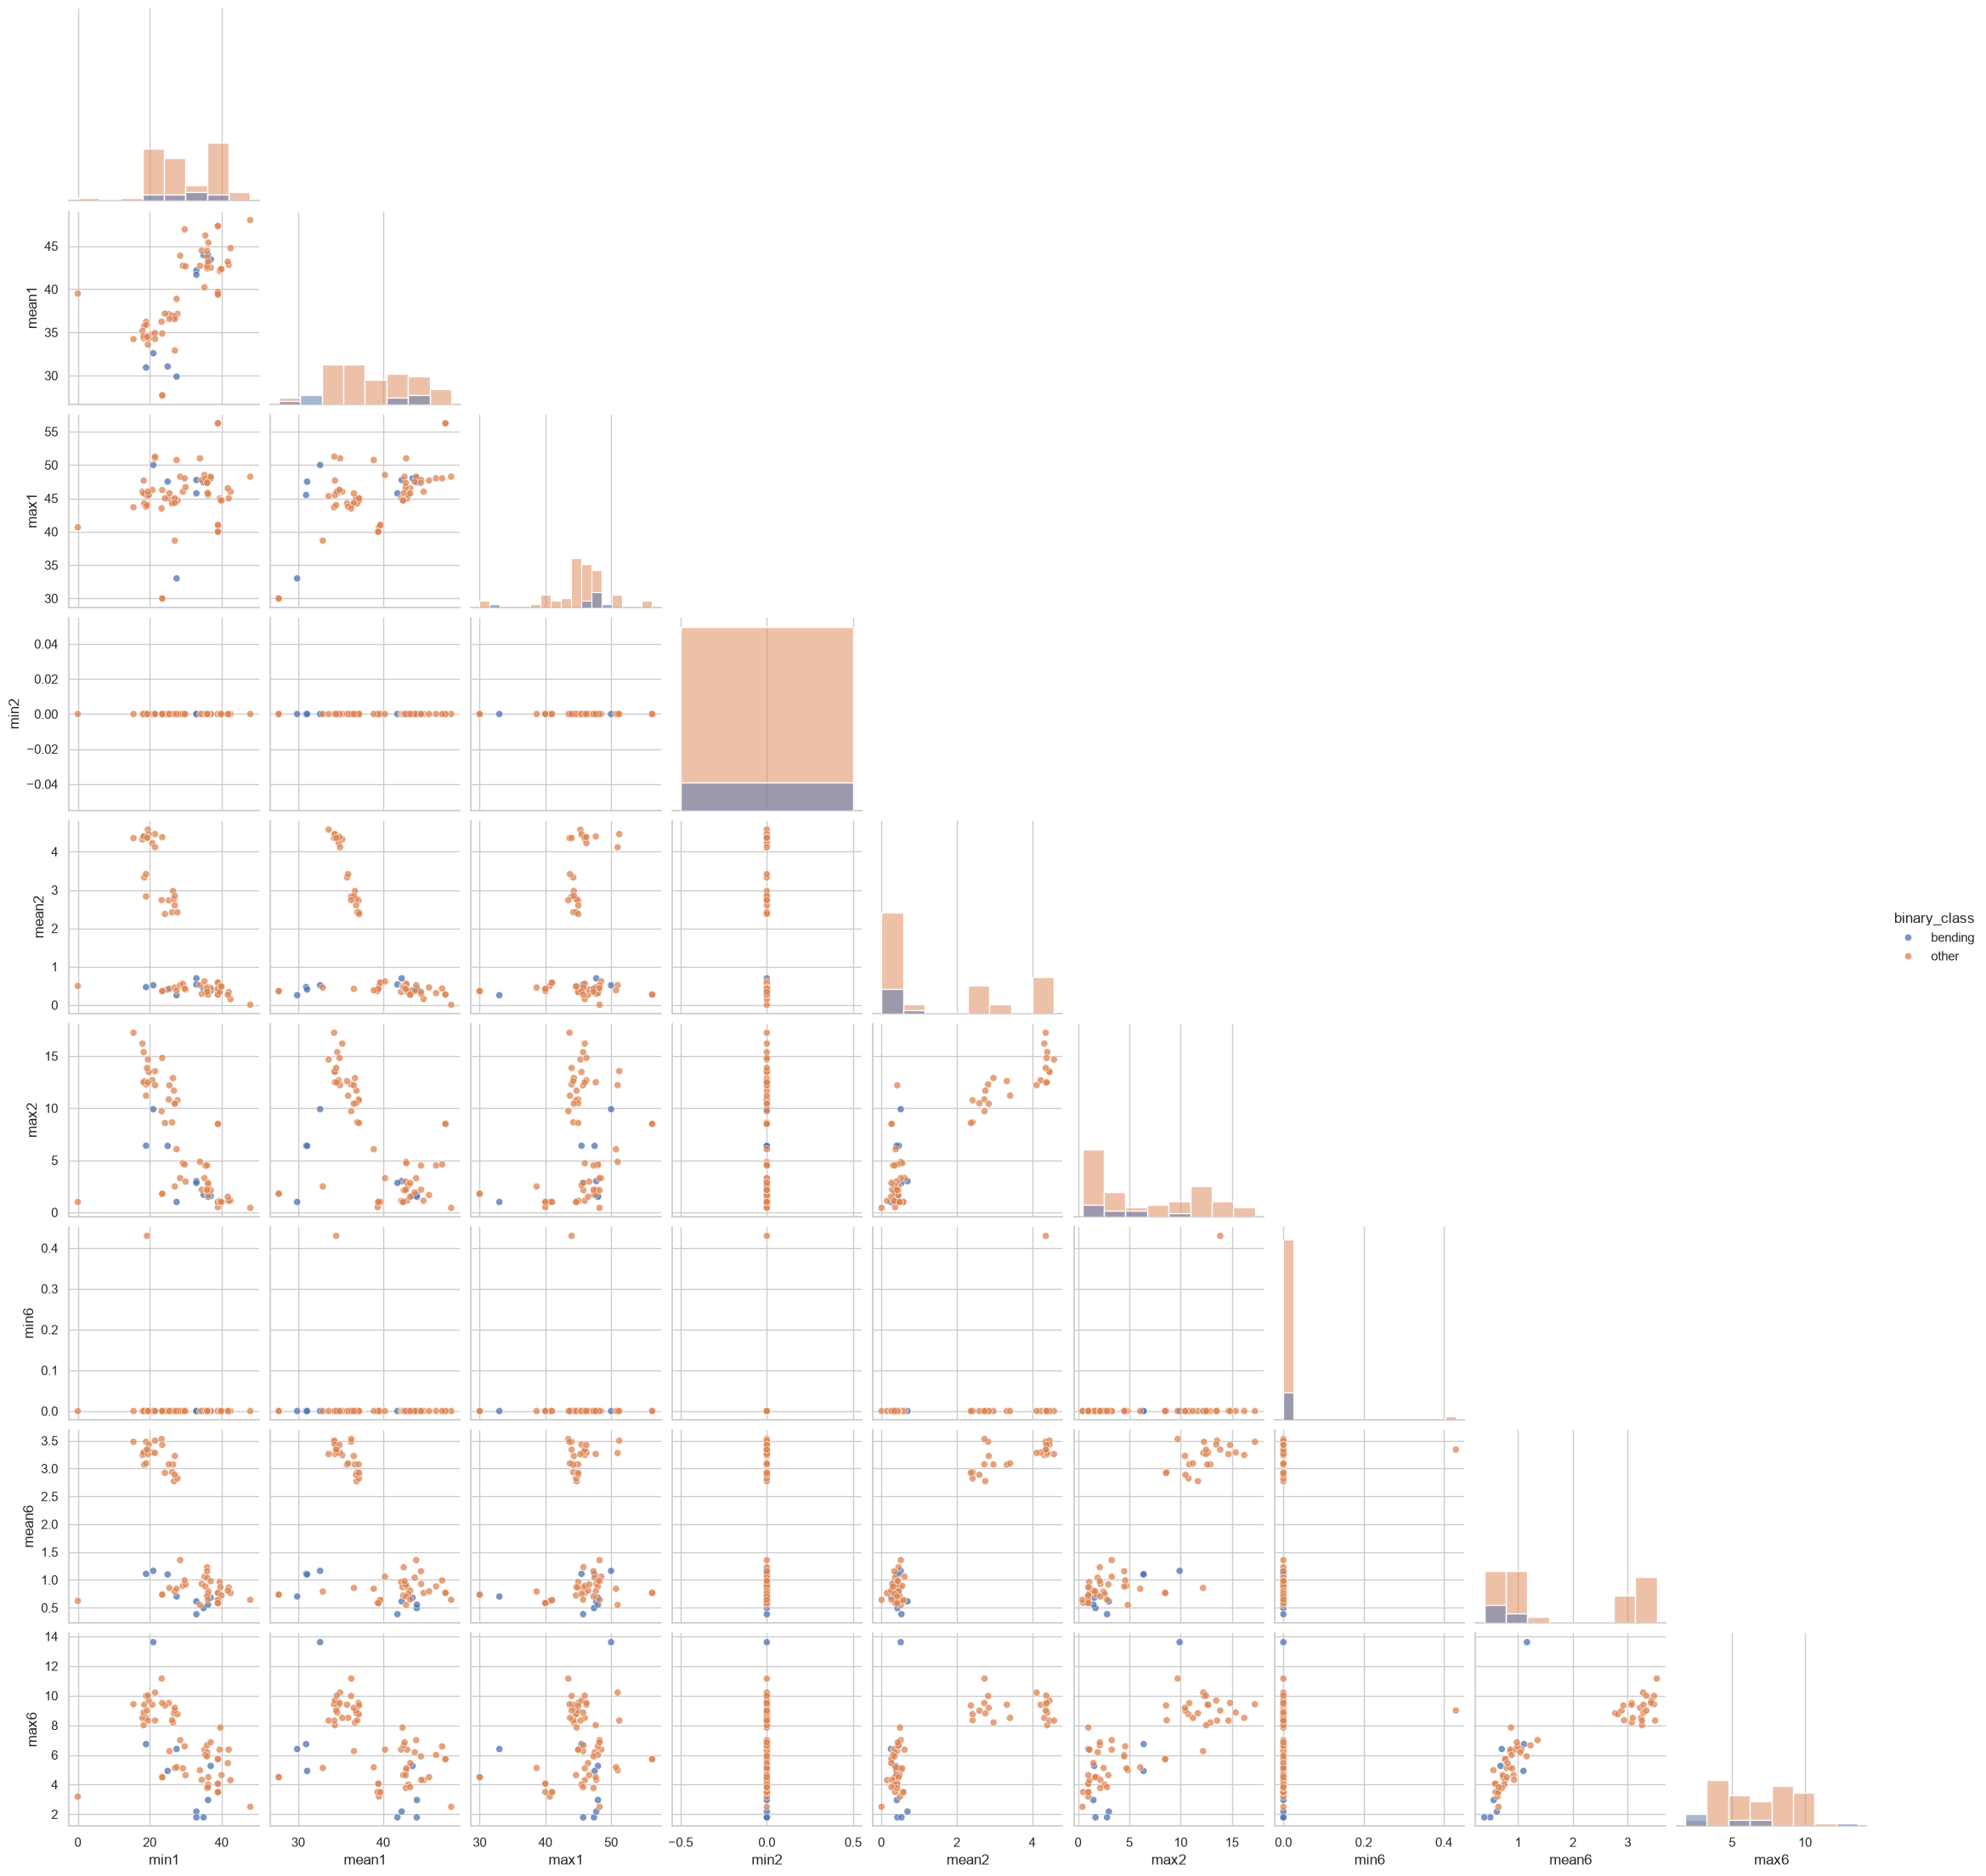

In [13]:
selected_series = [1, 2, 6]
selected_feature_types = ["min", "mean", "max"]

binary_columns = []

for series_number in selected_series:
    for feature_type in selected_feature_types:
        binary_columns.append(
            f"{feature_type}{series_number}"
        )

binary_train_df = (
    feature_df[
        feature_df["split"] == "train"
    ]
    .copy()
)

binary_train_df["binary_class"] = np.where(
    binary_train_df["activity"].isin(
        ["bending1", "bending2"]
    ),
    "bending",
    "other"
)

print("Training class counts:")
print(binary_train_df["binary_class"].value_counts())

sns.pairplot(
    binary_train_df[
        binary_columns + ["binary_class"]
    ],
    hue="binary_class",
    corner=True,
    diag_kind="hist",
    plot_kws={
        "alpha": 0.75,
        "s": 35
    }
)

plt.show()

### 2(a)i — Scatterplot Analysis

The training set contains **69 instances**, including:

- **9 bending instances**
- **60 non-bending instances**

Therefore, the binary classification problem is clearly imbalanced.

The pairwise scatterplots of the selected features from time series 1, 2, and 6 reveal several important patterns.

#### Time Series 1

The features `min1`, `mean1`, and `max1` show some differences between bending and non-bending activities, but there is still substantial overlap between the two classes.

The bending observations tend to occupy a relatively restricted region of the feature space, while the non-bending observations are more widely distributed. However, these features alone do not appear to provide complete separation.

#### Time Series 2

The feature `min2` is approximately zero for almost every observation in both classes. Therefore, it provides essentially no discriminatory information.

In contrast, `mean2` and `max2` appear more useful. The bending observations are concentrated at relatively low values of these features, whereas many non-bending observations have substantially larger values.

For example, several non-bending observations have much higher `mean2` and `max2` values than any bending observations. This suggests that the mean and maximum of time series 2 may help distinguish bending from other activities.

#### Time Series 6

A similar pattern appears for time series 6.

The feature `min6` is also approximately zero for most observations and therefore appears to have very limited classification value.

However, `mean6` and `max6` provide better separation. Bending observations tend to have relatively low values, while a group of non-bending observations has considerably larger means and maxima.

#### Overall Observation

Among the selected features, the **mean and maximum features from time series 2 and time series 6 appear to provide the clearest visual separation between bending and non-bending activities**.

The minimum features of time series 2 and 6 appear much less useful because they are nearly constant across the observations.

The features from time series 1 contain some discriminatory information, but the two classes overlap considerably.

Overall, no single feature appears to perfectly separate the two classes. Combining multiple features in a logistic regression model may therefore provide better classification performance than relying on any one feature individually.

The strong class imbalance (9 bending versus 60 non-bending training instances) should also be considered when evaluating the classifier.


### 2(a)ii

Break every time series into two approximately equal parts.

Each original instance therefore contains:

\[
6 \times 2 = 12
\]

time-series segments.

Extract minimum, mean, and maximum from both segments of
time series 1, 2, and 6 and compare the resulting scatterplots
with those from 2(a)i.

In [14]:
FEATURE_TYPES = [
    "min",
    "mean",
    "max"
]


def segment_statistics(series):
    return {
        "min": series.min(),
        "mean": series.mean(),
        "max": series.max()
    }


def extract_segment_features(
    frame,
    l,
    feature_types=FEATURE_TYPES
):
    """
    Divide each of the six time series into l approximately
    equal segments and extract selected statistics.
    """

    output = {}

    row_indices = np.arange(len(frame))
    segments = np.array_split(
        row_indices,
        l
    )

    for ts_number, column in enumerate(
        TIME_SERIES_COLUMNS,
        start=1
    ):
        for part_number, indices in enumerate(
            segments,
            start=1
        ):
            series = frame.loc[
                indices,
                column
            ]

            stats = segment_statistics(series)

            for feature_type in feature_types:
                name = (
                    f"{feature_type}_"
                    f"ts{ts_number}_"
                    f"part{part_number}"
                )

                output[name] = stats[
                    feature_type
                ]

    return output


def build_segment_feature_dataset(
    keys,
    l
):
    rows = []

    for activity, dataset_id in keys:
        frame = raw_instances[
            (activity, dataset_id)
        ]

        row = {
            "activity": activity,
            "dataset_id": dataset_id,
            "instance": (
                f"{activity}_dataset{dataset_id}"
            )
        }

        row.update(
            extract_segment_features(
                frame,
                l=l
            )
        )

        rows.append(row)

    return pd.DataFrame(rows)

In [15]:
train_keys = [
    (row.activity, row.dataset_id)
    for row in split_df.itertuples()
    if row.split == "train"
]

test_keys = [
    (row.activity, row.dataset_id)
    for row in split_df.itertuples()
    if row.split == "test"
]

print("Training instances:", len(train_keys))
print("Test instances:", len(test_keys))
print("Total:", len(train_keys) + len(test_keys))

Training instances: 69
Test instances: 19
Total: 88


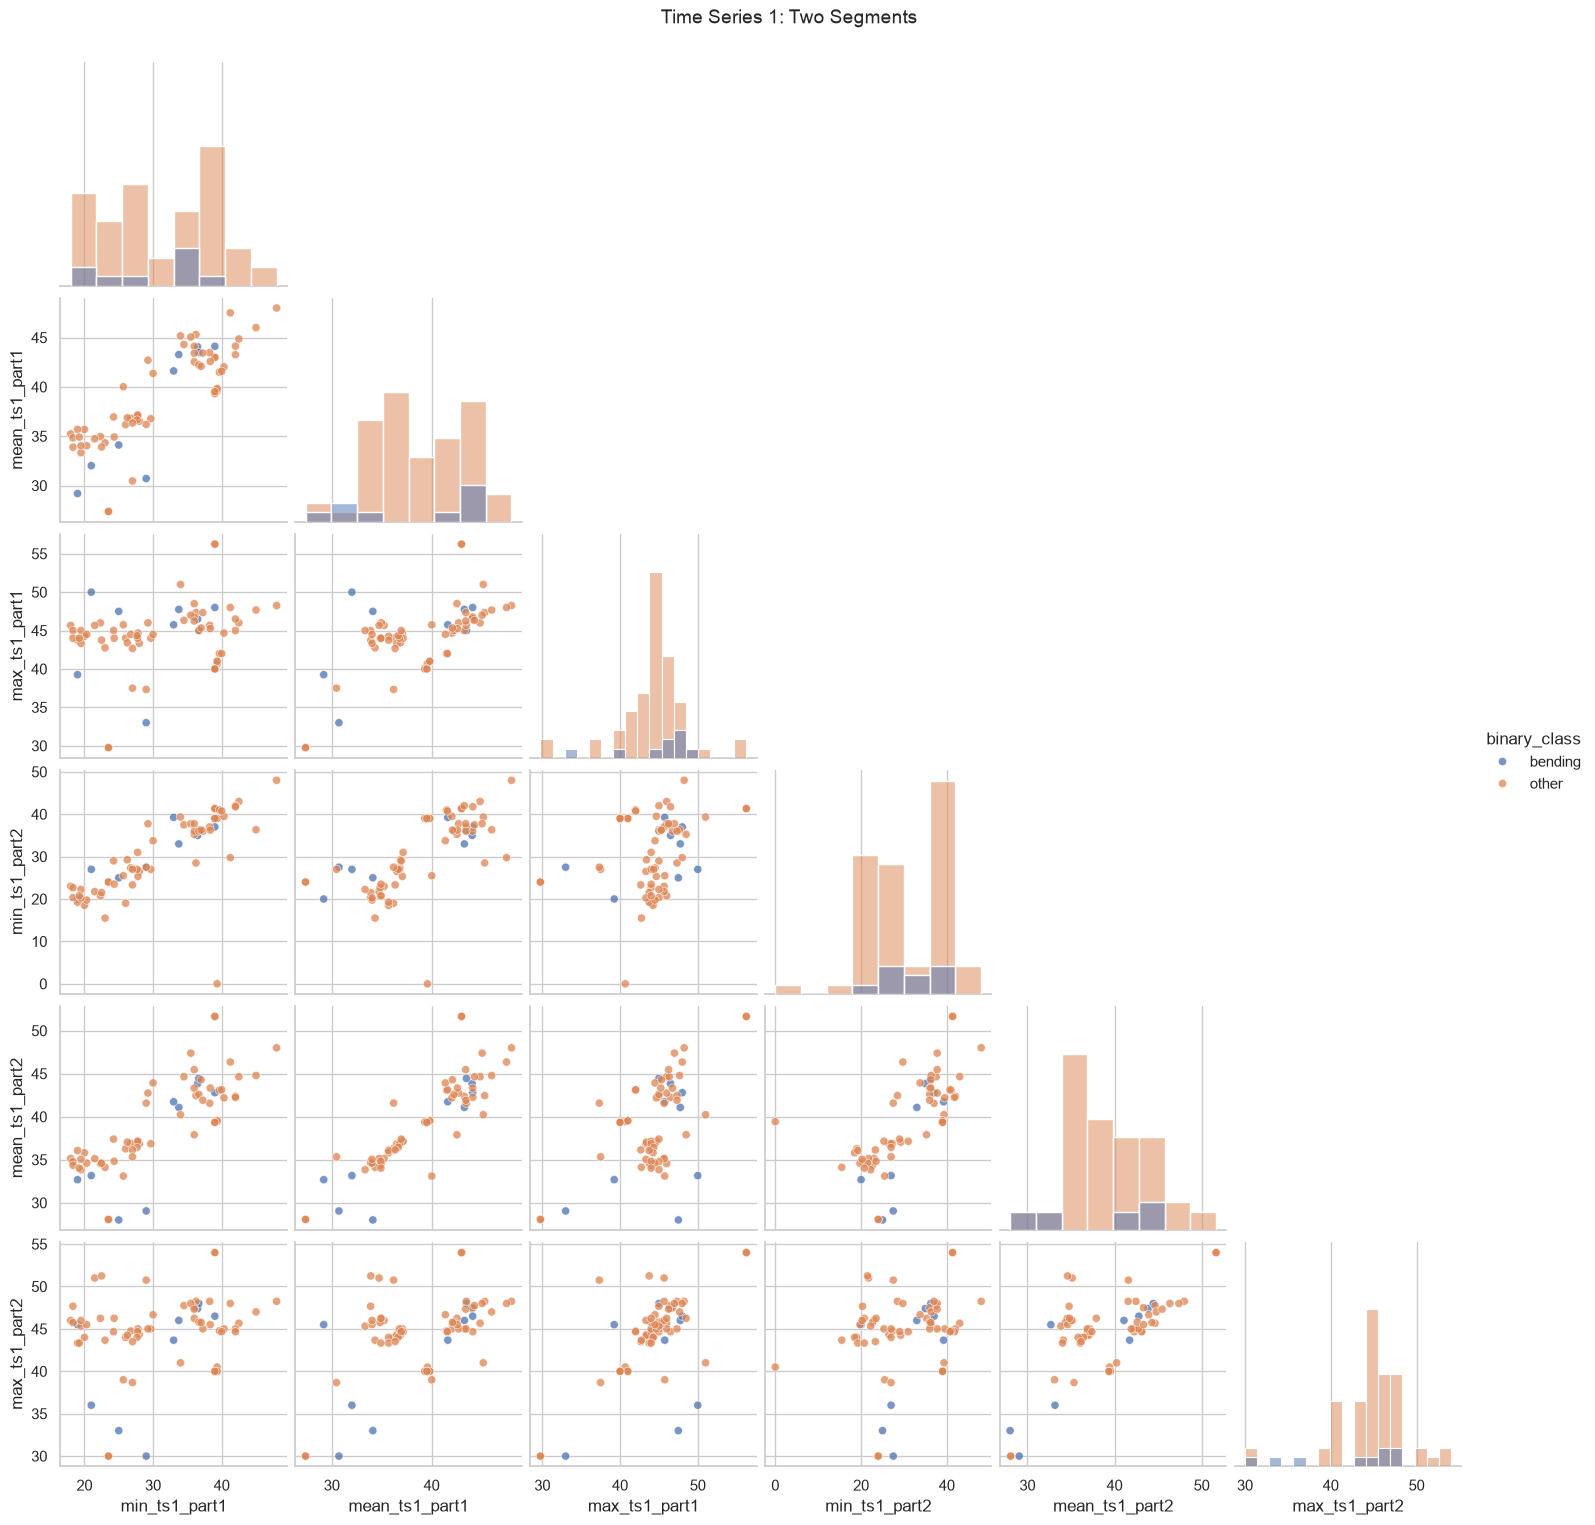

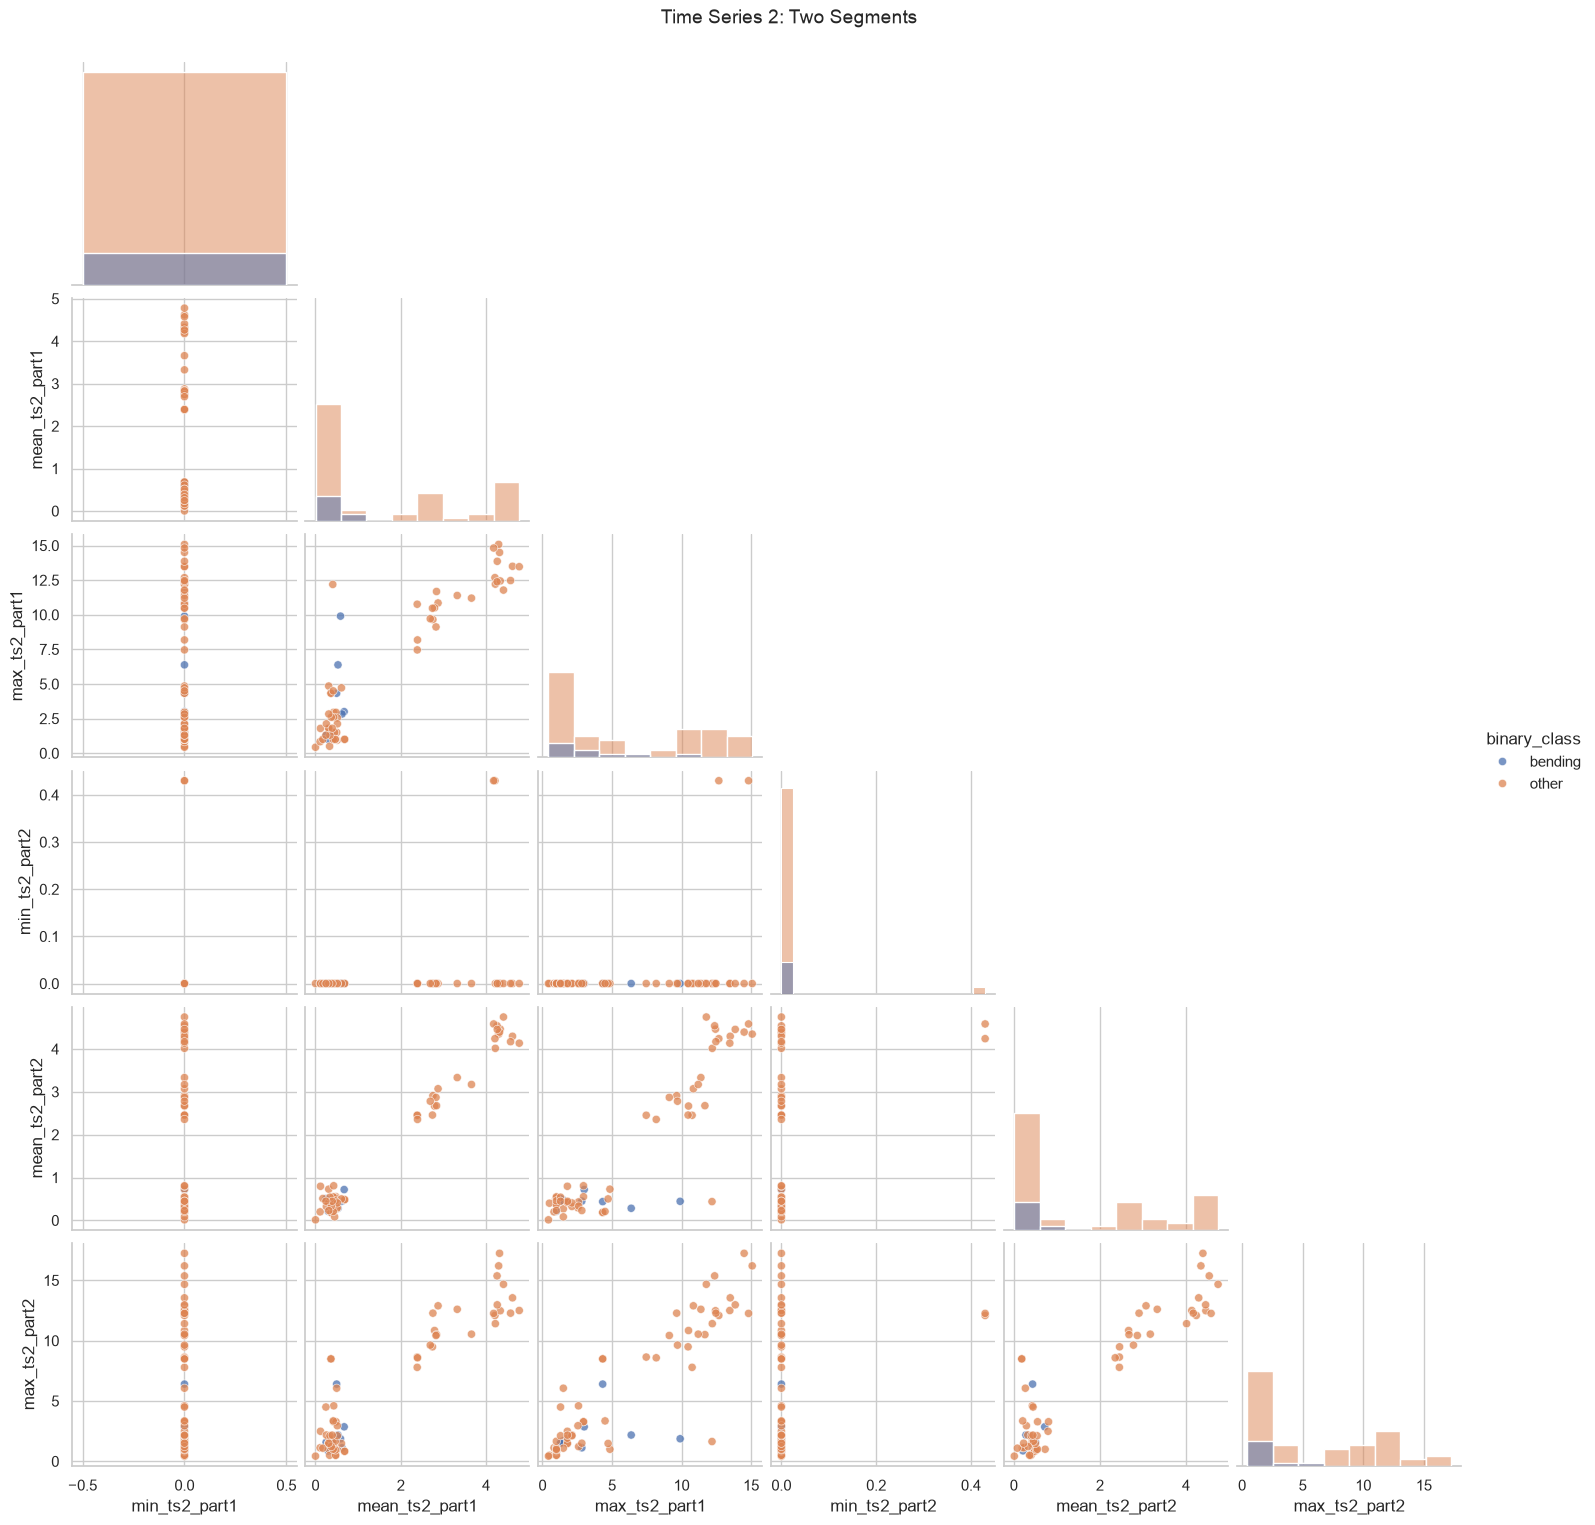

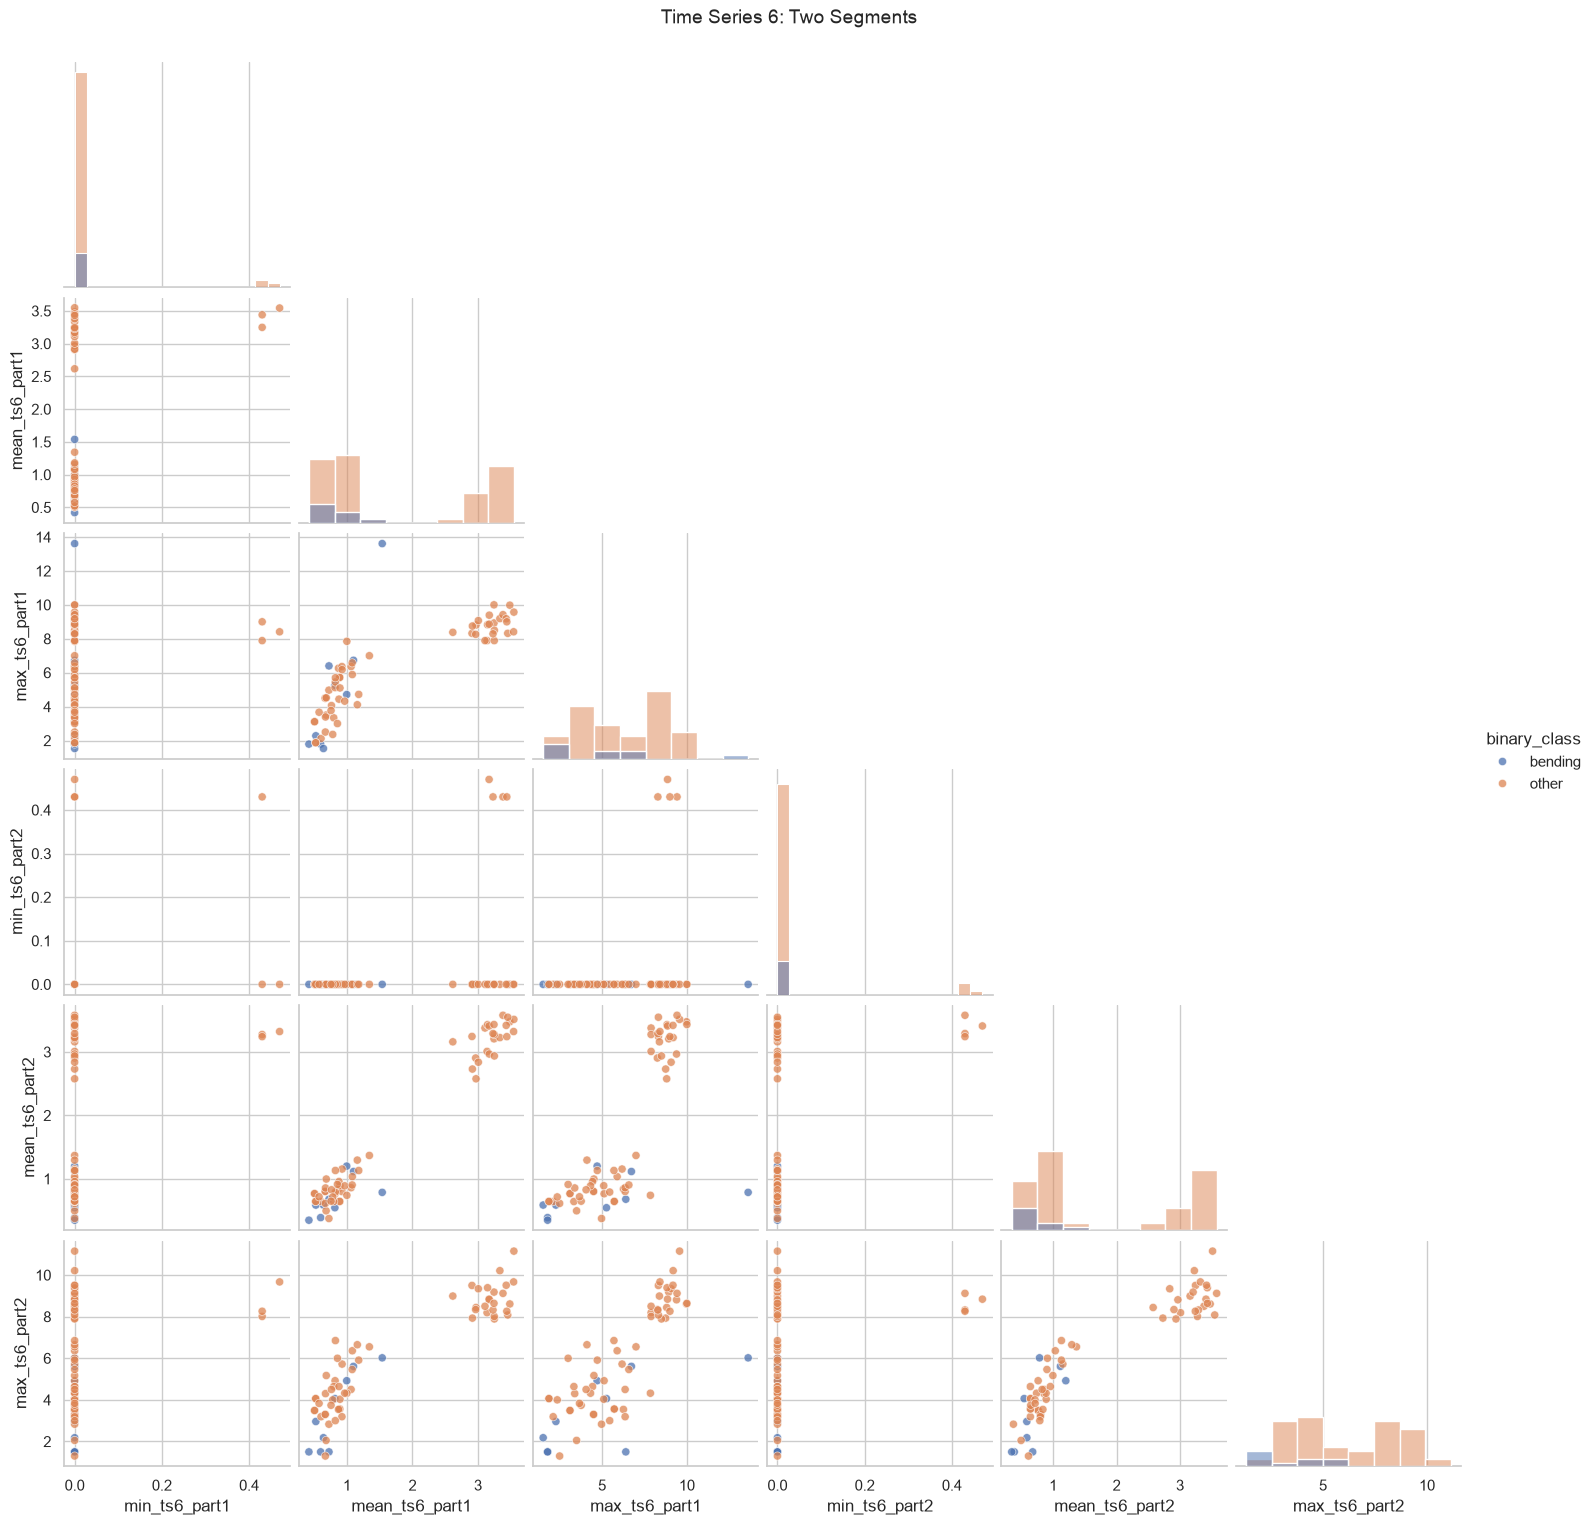

In [16]:
train_l2 = build_segment_feature_dataset(
    train_keys,
    l=2
)

train_l2["binary_class"] = np.where(
    train_l2["activity"].isin(
        ["bending1", "bending2"]
    ),
    "bending",
    "other"
)

for ts_number in [1, 2, 6]:

    columns = []

    for part in [1, 2]:
        for feature_type in FEATURE_TYPES:
            columns.append(
                f"{feature_type}_"
                f"ts{ts_number}_"
                f"part{part}"
            )

    sns.pairplot(
        train_l2[
            columns + ["binary_class"]
        ],
        hue="binary_class",
        corner=True,
        diag_kind="hist",
        plot_kws={
            "alpha": 0.75,
            "s": 35
        }
    )

    plt.figtext(
        0.5,
        1.01,
        f"Time Series {ts_number}: Two Segments",
        ha="center",
        fontsize=14
    )

    plt.show()

### 2(a)iii Logistic Regression, RFE, and Cross-Validation

For each

\[
l \in \{1,2,\ldots,20\},
\]

each original time series is divided into approximately equal
segments and minimum, mean, and maximum are extracted from each
segment.

Recursive Feature Elimination (RFE) is used for feature selection.

#### Correct Cross-Validation Procedure

Feature selection must be performed **inside each training fold**.

For each cross-validation split:

1. Fit the scaler using only the training fold.
2. Perform feature selection using only the training fold.
3. Fit logistic regression using the selected features.
4. Evaluate the model on the validation fold.

This prevents information from the validation fold from influencing
feature selection.

#### Incorrect Procedure

It would be incorrect to perform RFE once using the complete training
dataset and then perform cross-validation on the already-selected
features.

That procedure leaks information from validation observations into
the feature-selection process and can produce an optimistically biased
cross-validation accuracy.

Because bending observations are relatively rare, Stratified
5-Fold Cross-Validation is used to maintain approximately the same
class proportions in every fold.

In [17]:
def make_binary_dataset(l, keys=train_keys):

    data = build_segment_feature_dataset(
        keys,
        l=l
    )

    y = (
        data["activity"]
        .isin(["bending1", "bending2"])
        .astype(int)
    )

    metadata = [
        "activity",
        "dataset_id",
        "instance"
    ]

    feature_names = [
        col
        for col in data.columns
        if col not in metadata
    ]

    X = data[feature_names]

    return X, y, feature_names


binary_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

X_check, y_check, _ = make_binary_dataset(1)

print("Training observations:", len(y_check))
print("\nClass counts:")
print(y_check.value_counts())

Training observations: 69

Class counts:
activity
0    60
1     9
Name: count, dtype: int64


In [18]:
binary_cv_records = []

for l in range(1, 21):

    print(f"Processing l = {l}")

    X_l, y_l, feature_names_l = (
        make_binary_dataset(l)
    )

    base_logistic = Pipeline([
        (
            "scale",
            StandardScaler()
        ),
        (
            "logit",
            LogisticRegression(
                C=1e6,
                solver="liblinear",
                max_iter=5000,
                random_state=RANDOM_STATE
            )
        )
    ])

    rfecv = RFECV(
        estimator=base_logistic,
        step=1,
        cv=binary_cv,
        scoring="accuracy",
        min_features_to_select=1,
        n_jobs=-1,
        importance_getter=(
            "named_steps.logit.coef_"
        )
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        rfecv.fit(
            X_l,
            y_l
        )

    best_cv_accuracy_l = np.max(
        rfecv.cv_results_[
            "mean_test_score"
        ]
    )

    binary_cv_records.append({
        "l": l,
        "p": rfecv.n_features_,
        "number_of_original_features":
            X_l.shape[1],
        "cv_accuracy":
            best_cv_accuracy_l
    })


binary_cv_results = pd.DataFrame(
    binary_cv_records
)

display(binary_cv_results)

Processing l = 1
Processing l = 2
Processing l = 3
Processing l = 4
Processing l = 5
Processing l = 6
Processing l = 7
Processing l = 8
Processing l = 9
Processing l = 10
Processing l = 11
Processing l = 12
Processing l = 13
Processing l = 14
Processing l = 15
Processing l = 16
Processing l = 17
Processing l = 18
Processing l = 19
Processing l = 20


,l,p,number_of_original_features,cv_accuracy
0,1,9,18,0.985714
1,2,7,36,0.957143
2,3,8,54,0.957143
3,4,17,72,0.957143
4,5,4,90,0.942857
5,6,13,108,0.957143
6,7,6,126,0.957143
7,8,30,144,0.928571
8,9,2,162,0.942857
9,10,1,180,0.941758


In [19]:
binary_cv_results_sorted = (
    binary_cv_results
    .sort_values(
        [
            "cv_accuracy",
            "p",
            "l"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
    .reset_index(drop=True)
)

display(binary_cv_results_sorted)

best_binary_row = (
    binary_cv_results_sorted.iloc[0]
)

best_l = int(
    best_binary_row["l"]
)

best_p = int(
    best_binary_row["p"]
)

best_cv_accuracy = float(
    best_binary_row["cv_accuracy"]
)

print("Best l =", best_l)
print("Best p =", best_p)
print(
    "Best 5-fold CV accuracy =",
    best_cv_accuracy
)

,l,p,number_of_original_features,cv_accuracy
0,1,9,18,0.985714
1,19,3,342,0.971429
2,20,3,360,0.971429
3,18,1,324,0.957143
4,12,1,216,0.957143
5,16,1,288,0.957143
6,17,4,306,0.957143
7,7,6,126,0.957143
8,2,7,36,0.957143
9,3,8,54,0.957143


Best l = 1
Best p = 9
Best 5-fold CV accuracy = 0.9857142857142858


In [20]:
X_train_best, y_train_binary, binary_feature_names = (
    make_binary_dataset(
        best_l,
        train_keys
    )
)

binary_base_estimator = Pipeline([
    (
        "scale",
        StandardScaler()
    ),
    (
        "logit",
        LogisticRegression(
            C=1e6,
            solver="liblinear",
            max_iter=5000,
            random_state=RANDOM_STATE
        )
    )
])

best_binary_rfecv = RFECV(
    estimator=binary_base_estimator,
    step=1,
    cv=binary_cv,
    scoring="accuracy",
    min_features_to_select=1,
    n_jobs=-1,
    importance_getter=(
        "named_steps.logit.coef_"
    )
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    best_binary_rfecv.fit(
        X_train_best,
        y_train_binary
    )


selected_binary_features = np.array(
    binary_feature_names
)[
    best_binary_rfecv.support_
]

print(
    "Selected number of features:",
    len(selected_binary_features)
)

print("\nSelected features:")

for name in selected_binary_features:
    print(name)

Selected number of features: 9

Selected features:
min_ts1_part1
max_ts2_part1
min_ts3_part1
mean_ts3_part1
mean_ts4_part1
max_ts4_part1
min_ts5_part1
mean_ts5_part1
max_ts5_part1


### 2(a)iv Training Performance

Report:

- confusion matrix
- ROC curve
- AUC
- logistic regression coefficients
- p-values

Training Accuracy: 1.0
Training AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

       Other       1.00      1.00      1.00        60
     Bending       1.00      1.00      1.00         9

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



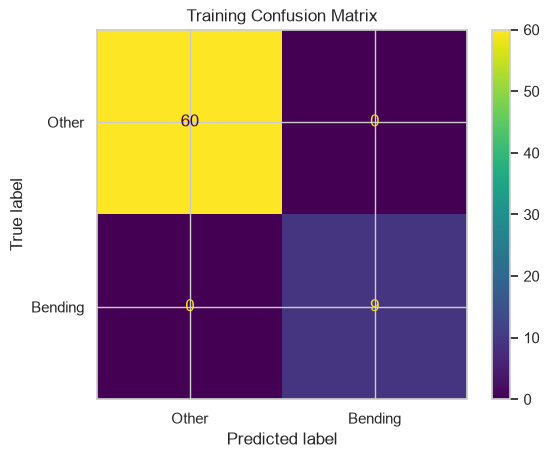

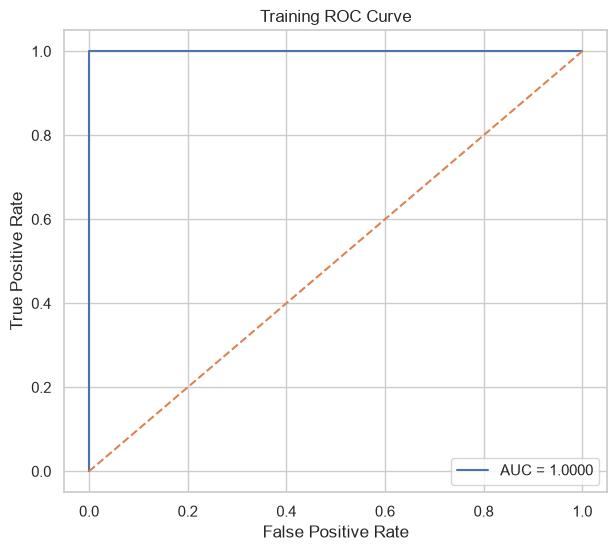

In [21]:
train_pred_binary = (
    best_binary_rfecv.predict(
        X_train_best
    )
)

train_prob_binary = (
    best_binary_rfecv.predict_proba(
        X_train_best
    )[:, 1]
)

train_accuracy_binary = accuracy_score(
    y_train_binary,
    train_pred_binary
)

train_auc_binary = roc_auc_score(
    y_train_binary,
    train_prob_binary
)

print(
    "Training Accuracy:",
    train_accuracy_binary
)

print(
    "Training AUC:",
    train_auc_binary
)

print("\nClassification Report:")

print(
    classification_report(
        y_train_binary,
        train_pred_binary,
        target_names=[
            "Other",
            "Bending"
        ]
    )
)


ConfusionMatrixDisplay.from_predictions(
    y_train_binary,
    train_pred_binary,
    display_labels=[
        "Other",
        "Bending"
    ]
)

plt.title(
    "Training Confusion Matrix"
)

plt.show()


fpr_train, tpr_train, _ = roc_curve(
    y_train_binary,
    train_prob_binary
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_train,
    tpr_train,
    label=f"AUC = {train_auc_binary:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    "Training ROC Curve"
)

plt.legend()
plt.grid(True)
plt.show()

In [22]:
selected_positions = np.where(
    best_binary_rfecv.support_
)[0]

X_selected_raw = (
    X_train_best.iloc[
        :,
        selected_positions
    ]
    .copy()
)

final_binary_pipeline = (
    best_binary_rfecv.estimator_
)

final_scaler = (
    final_binary_pipeline
    .named_steps["scale"]
)

X_selected_scaled = (
    final_scaler.transform(
        X_selected_raw
    )
)

X_selected_scaled_df = pd.DataFrame(
    X_selected_scaled,
    columns=selected_binary_features,
    index=X_selected_raw.index
)

X_statsmodels = sm.add_constant(
    X_selected_scaled_df
)

try:

    glm_binary = sm.GLM(
        y_train_binary,
        X_statsmodels,
        family=sm.families.Binomial()
    ).fit()

    binary_parameter_table = pd.DataFrame({
        "Coefficient": glm_binary.params,
        "p-value": glm_binary.pvalues
    })

    display(
        binary_parameter_table
    )

    print(
        glm_binary.summary()
    )

except Exception as error:

    print(
        "Statsmodels could not produce "
        "stable p-values:"
    )

    print(error)

/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1269

,Coefficient,p-value
const,-34.710585,0.998850
min_ts1_part1,-9.689232,0.999608
max_ts2_part1,-11.030407,0.999694
min_ts3_part1,-8.916506,0.999893
mean_ts3_part1,-7.051573,0.999837
mean_ts4_part1,-5.911783,0.999943
max_ts4_part1,8.038640,0.999847
min_ts5_part1,24.752763,0.999637
mean_ts5_part1,-4.879953,0.999944
max_ts5_part1,23.669396,0.999208


                 Generalized Linear Model Regression Results                  
Dep. Variable:               activity   No. Observations:                   69
Model:                            GLM   Df Residuals:                       59
Model Family:                Binomial   Df Model:                            9
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.8670e-09
Date:                Fri, 16 Oct 2026   Deviance:                   3.7341e-09
Time:                        12:30:53   Pearson chi2:                 1.87e-09
No. Iterations:                    24   Pseudo R-squ. (CS):             0.5390
Covariance Type:            nonrobust                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -34.7106   2.41e+04     -0.

### 2(a)iv — Training Model Interpretation

The fitted logistic regression model shows strong evidence of
complete or near-complete separation in the training data.

The selected model contains the following features:

- `min_ts1_part1`
- `max_ts2_part1`
- `min_ts3_part1`
- `mean_ts3_part1`
- `mean_ts4_part1`
- `max_ts4_part1`
- `min_ts5_part1`
- `mean_ts5_part1`
- `max_ts5_part1`

The estimated coefficients are relatively large in magnitude.
For example:

- Intercept = -34.71
- `min_ts5_part1` = 24.75
- `max_ts5_part1` = 23.67
- `max_ts2_part1` = -11.03

However, the standard errors are extremely large, on the order of
\(10^4\) to \(10^5\), and the associated p-values are all close to 1.

This does **not** mean that the selected features are necessarily
unimportant. Instead, these results indicate that the maximum-
likelihood estimates of the logistic regression parameters are
numerically unstable.

The model has a log-likelihood extremely close to zero and a deviance
close to zero, suggesting that the selected features almost perfectly
separate bending from non-bending observations in the training set.

This is a classic symptom of **complete or near-complete separation**.
When the classes can be separated nearly perfectly, the logistic
regression coefficients tend toward very large magnitudes and their
standard errors become extremely large. Consequently, conventional
Wald p-values become unreliable.

Therefore, the p-values reported by this unregularized GLM should not
be interpreted as reliable evidence for or against the importance of
individual predictors.

The predictive performance of the classifier should instead be
evaluated using the confusion matrix, ROC curve, AUC, cross-validation
accuracy, and test-set performance.

The instability observed here also motivates the use of regularized
logistic regression, particularly the L1-penalized model considered
later in Section 2(b).

### 2(a)v Test-Set Performance

Apply the selected classifier to the test set using the same value
of \(l\) and the same feature extraction procedure used for the
training set.

Compare test accuracy with the cross-validation accuracy.

Cross-validation accuracy: 0.9857142857142858
Test accuracy: 0.9473684210526315
Test error: 0.052631578947368474
Test AUC: 1.0


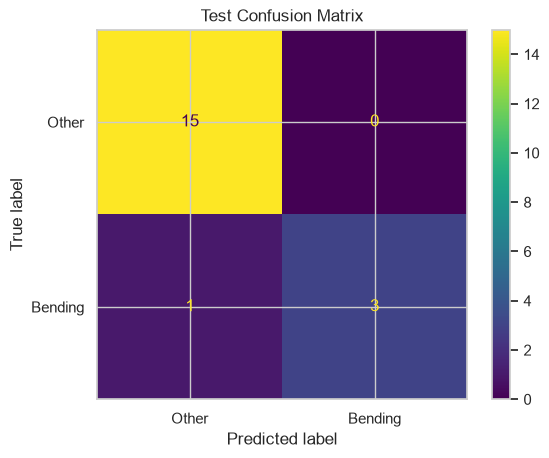

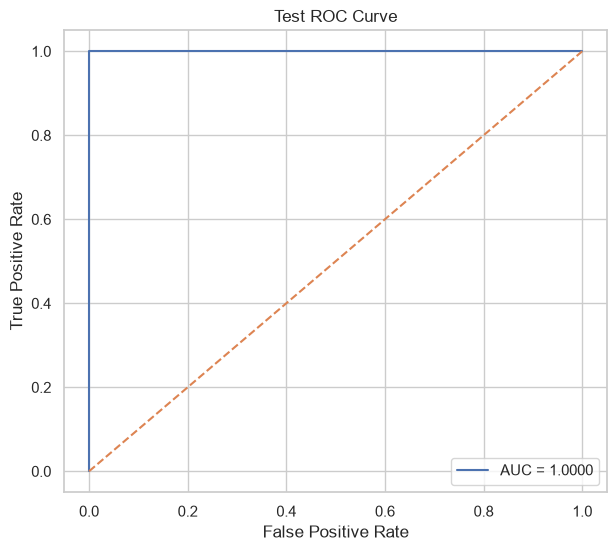

In [23]:
X_test_best, y_test_binary, _ = (
    make_binary_dataset(
        best_l,
        test_keys
    )
)

test_pred_binary = (
    best_binary_rfecv.predict(
        X_test_best
    )
)

test_prob_binary = (
    best_binary_rfecv.predict_proba(
        X_test_best
    )[:, 1]
)

test_accuracy_binary = accuracy_score(
    y_test_binary,
    test_pred_binary
)

test_auc_binary = roc_auc_score(
    y_test_binary,
    test_prob_binary
)

print(
    "Cross-validation accuracy:",
    best_cv_accuracy
)

print(
    "Test accuracy:",
    test_accuracy_binary
)

print(
    "Test error:",
    1 - test_accuracy_binary
)

print(
    "Test AUC:",
    test_auc_binary
)


ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    test_pred_binary,
    display_labels=[
        "Other",
        "Bending"
    ]
)

plt.title(
    "Test Confusion Matrix"
)

plt.show()


fpr_test, tpr_test, _ = roc_curve(
    y_test_binary,
    test_prob_binary
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_test,
    tpr_test,
    label=f"AUC = {test_auc_binary:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Curve")

plt.legend()
plt.grid(True)
plt.show()

### 2(a)v — Test-Set Performance and Interpretation

The selected logistic regression classifier was evaluated on the held-out test set using the same segmentation and feature-extraction procedure used for the training data.

The results are:

- **5-fold cross-validation accuracy:** 0.9857
- **Test accuracy:** 0.9474
- **Test error:** 0.0526
- **Test AUC:** 1.0000

The test confusion matrix is:

\[
\begin{bmatrix}
15 & 0 \\
1 & 3
\end{bmatrix}
\]

where the rows represent the true classes and the columns represent the predicted classes.

Therefore:

- 15 non-bending observations were correctly classified as non-bending.
- 0 non-bending observations were incorrectly classified as bending.
- 3 bending observations were correctly classified as bending.
- 1 bending observation was incorrectly classified as non-bending.

This gives:

- **Specificity:** \(15/15 = 1.00\)
- **Sensitivity:** \(3/4 = 0.75\)
- **Precision for bending:** \(3/3 = 1.00\)

The test accuracy of 94.74% is slightly lower than the cross-validation accuracy of 98.57%, with a difference of about 3.8 percentage points. This suggests that the cross-validation estimate was somewhat optimistic, but the classifier still generalizes well to the unseen test set.

The ROC curve achieves an AUC of 1.0, indicating that the model perfectly ranks the bending observations above the non-bending observations in terms of predicted probability. However, the confusion matrix shows that one bending observation is still misclassified at the default probability threshold of 0.5.

Overall, the classifier performs very well on the test data, although its sensitivity to the minority bending class is lower than its specificity for the majority non-bending class. This is important because the training data are imbalanced.


### 2(a)vi Separation and Logistic Regression Stability

In [24]:
logistic_coefficients = (
    final_binary_pipeline
    .named_steps["logit"]
    .coef_[0]
)

print(
    "Training accuracy:",
    train_accuracy_binary
)

print(
    "Maximum absolute coefficient:",
    np.max(
        np.abs(
            logistic_coefficients
        )
    )
)

print(
    "Minimum predicted probability:",
    train_prob_binary.min()
)

print(
    "Maximum predicted probability:",
    train_prob_binary.max()
)

print(
    "Predictions below 0.01:",
    np.sum(
        train_prob_binary < 0.01
    )
)

print(
    "Predictions above 0.99:",
    np.sum(
        train_prob_binary > 0.99
    )
)

Training accuracy: 1.0
Maximum absolute coefficient: 10.742184598359032
Minimum predicted probability: 3.7222216986435424e-19
Maximum predicted probability: 1.0
Predictions below 0.01: 60
Predictions above 0.99: 9


### 2(a)vi — Separation and Logistic Regression Stability

The diagnostics provide very strong evidence of complete or near-complete separation in the training data.

The model achieves:

- **Training accuracy:** 1.0000
- **Maximum absolute coefficient:** 10.7422
- **Minimum predicted probability:** approximately \(3.72\times10^{-19}\)
- **Maximum predicted probability:** 1.0000
- **60 observations with predicted probability below 0.01**
- **9 observations with predicted probability above 0.99**

Since the training set contains 60 non-bending observations and 9 bending observations, these probability results show that the classifier assigns nearly all non-bending observations probabilities extremely close to 0 and nearly all bending observations probabilities extremely close to 1.

This indicates that the two classes are almost perfectly separated in the selected feature space.

Such separation creates instability in unregularized logistic regression. When complete or near-complete separation occurs, the maximum-likelihood estimates of the logistic regression coefficients can become very large in magnitude, and the corresponding standard errors and Wald p-values become unreliable.

This behavior is consistent with the results obtained earlier, where the GLM produced very large standard errors and p-values close to 1 despite perfect training classification.

Therefore, the classes appear sufficiently well separated to cause instability in the estimation of the unregularized logistic regression parameters.

This motivates the use of regularized logistic regression, such as the L1-penalized model considered later in Section 2(b), which can produce more stable coefficient estimates.

In [25]:
binary_class_counts = pd.Series(
    y_train_binary
).value_counts().sort_index()

binary_class_proportions = pd.Series(
    y_train_binary
).value_counts(
    normalize=True
).sort_index()

print("Class counts:")
print(binary_class_counts)

print("\nClass proportions:")
print(binary_class_proportions)

Class counts:
activity
0    60
1     9
Name: count, dtype: int64

Class proportions:
activity
0    0.869565
1    0.130435
Name: proportion, dtype: float64


### 2(a)vii Case-Control Sampling

The training data contain many more non-bending observations than
bending observations.

To reduce the effect of class imbalance, case-control sampling is
used to create a balanced sample.

Because case-control sampling changes the class prior, the intercept
of the logistic regression model must be adjusted after fitting.

In [26]:
rng = np.random.default_rng(
    RANDOM_STATE
)

X_case_control = (
    X_selected_scaled_df.copy()
)

y_case_control = (
    y_train_binary.reset_index(
        drop=True
    )
)

X_case_control = (
    X_case_control.reset_index(
        drop=True
    )
)

case_indices = np.where(
    y_case_control.to_numpy() == 1
)[0]

control_indices = np.where(
    y_case_control.to_numpy() == 0
)[0]

sampled_control_indices = rng.choice(
    control_indices,
    size=len(case_indices),
    replace=False
)

balanced_indices = np.concatenate([
    case_indices,
    sampled_control_indices
])

rng.shuffle(
    balanced_indices
)

X_balanced = (
    X_case_control.iloc[
        balanced_indices
    ]
    .reset_index(drop=True)
)

y_balanced = (
    y_case_control.iloc[
        balanced_indices
    ]
    .reset_index(drop=True)
)

print(
    "Original class proportions:"
)

print(
    y_case_control.value_counts(
        normalize=True
    )
)

print(
    "\nCase-control sample proportions:"
)

print(
    y_balanced.value_counts(
        normalize=True
    )
)


X_balanced_sm = sm.add_constant(
    X_balanced
)

case_control_model = sm.GLM(
    y_balanced,
    X_balanced_sm,
    family=sm.families.Binomial()
).fit()


adjusted_params = (
    case_control_model
    .params
    .copy()
)

population_prior = (
    y_case_control.mean()
)

sample_prior = (
    y_balanced.mean()
)

intercept_adjustment = (
    np.log(
        population_prior /
        (1 - population_prior)
    )
    -
    np.log(
        sample_prior /
        (1 - sample_prior)
    )
)

adjusted_params["const"] += (
    intercept_adjustment
)

display(
    pd.DataFrame({
        "Case-Control Coefficient":
            case_control_model.params,
        "Adjusted Coefficient":
            adjusted_params
    })
)

Original class proportions:
activity
0    0.869565
1    0.130435
Name: proportion, dtype: float64

Case-control sample proportions:
activity
0    0.5
1    0.5
Name: proportion, dtype: float64


/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


,Case-Control Coefficient,Adjusted Coefficient
const,-9.480017,-11.377137
min_ts1_part1,-8.144844,-8.144844
max_ts2_part1,-15.216149,-15.216149
min_ts3_part1,-0.443875,-0.443875
mean_ts3_part1,-35.522875,-35.522875
mean_ts4_part1,7.953686,7.953686
max_ts4_part1,-3.516503,-3.516503
min_ts5_part1,3.640840,3.640840
mean_ts5_part1,13.716834,13.716834
max_ts5_part1,15.717526,15.717526


Case-control adjusted accuracy: 0.8405797101449275
Case-control adjusted AUC: 0.9037037037037037


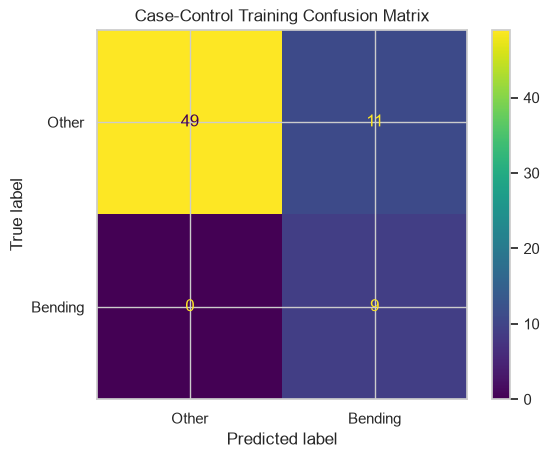

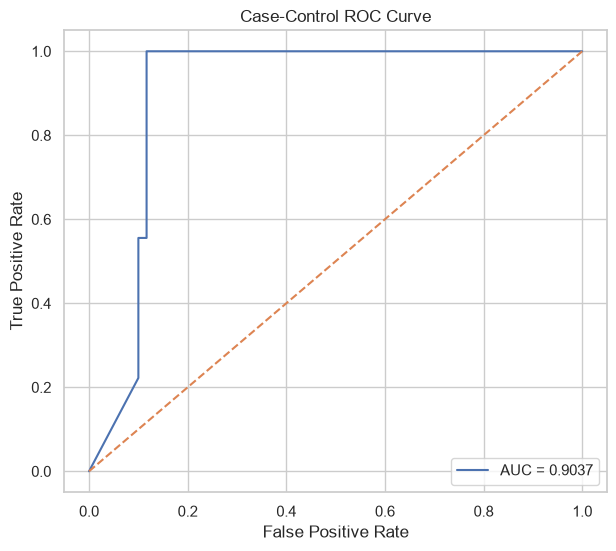

In [27]:
X_full_sm = sm.add_constant(
    X_case_control
)

linear_predictor_cc = (
    X_full_sm.to_numpy()
    @ adjusted_params.to_numpy()
)

prob_case_control = expit(
    linear_predictor_cc
)

pred_case_control = (
    prob_case_control >= 0.5
).astype(int)

cc_accuracy = accuracy_score(
    y_case_control,
    pred_case_control
)

cc_auc = roc_auc_score(
    y_case_control,
    prob_case_control
)

print(
    "Case-control adjusted accuracy:",
    cc_accuracy
)

print(
    "Case-control adjusted AUC:",
    cc_auc
)


ConfusionMatrixDisplay.from_predictions(
    y_case_control,
    pred_case_control,
    display_labels=[
        "Other",
        "Bending"
    ]
)

plt.title(
    "Case-Control Training Confusion Matrix"
)

plt.show()


fpr_cc, tpr_cc, _ = roc_curve(
    y_case_control,
    prob_case_control
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_cc,
    tpr_cc,
    label=f"AUC = {cc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    "Case-Control ROC Curve"
)

plt.legend()
plt.grid(True)
plt.show()

## 2(b) Binary Classification Using L1-Penalized Logistic Regression

### 2(b)i

Use L1-penalized logistic regression and cross-validation to select:

\[
(l, C)
\]

where:

- \(l\) is the number of segments;
- \(C\) is the inverse regularization strength.

Feature standardization is performed inside the cross-validation
pipeline to avoid data leakage.

In [28]:
C_values = np.logspace(
    -4,
    4,
    15
)

l1_binary_records = []

for l in range(1, 21):

    print(f"Processing l = {l}")

    X_l, y_l, _ = (
        make_binary_dataset(
            l,
            train_keys
        )
    )

    pipeline_l1 = Pipeline([
        (
            "scale",
            StandardScaler()
        ),
        (
            "logit",
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                max_iter=5000,
                random_state=RANDOM_STATE
            )
        )
    ])

    grid_l1 = GridSearchCV(
        estimator=pipeline_l1,
        param_grid={
            "logit__C": C_values
        },
        cv=binary_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        grid_l1.fit(
            X_l,
            y_l
        )

    l1_binary_records.append({
        "l": l,
        "best_C":
            grid_l1.best_params_[
                "logit__C"
            ],
        "cv_accuracy":
            grid_l1.best_score_
    })


l1_binary_results = pd.DataFrame(
    l1_binary_records
)

display(
    l1_binary_results
)

Processing l = 1
Processing l = 2
Processing l = 3
Processing l = 4
Processing l = 5
Processing l = 6
Processing l = 7
Processing l = 8
Processing l = 9
Processing l = 10
Processing l = 11
Processing l = 12
Processing l = 13
Processing l = 14
Processing l = 15
Processing l = 16
Processing l = 17
Processing l = 18
Processing l = 19
Processing l = 20


,l,best_C,cv_accuracy
0,1,3.727594,0.971429
1,2,1.000000,0.957143
2,3,0.268270,0.971429
3,4,1.000000,0.971429
4,5,3.727594,0.942857
5,6,3.727594,0.957143
6,7,51.794747,0.957143
7,8,1.000000,0.942857
8,9,13.894955,0.942857
9,10,51.794747,0.942857


In [29]:
best_l1_row = (
    l1_binary_results
    .sort_values(
        [
            "cv_accuracy",
            "l"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)

best_l_l1 = int(
    best_l1_row["l"]
)

best_C_l1 = float(
    best_l1_row["best_C"]
)

best_cv_l1 = float(
    best_l1_row["cv_accuracy"]
)

print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print(
    "Best CV accuracy:",
    best_cv_l1
)


X_train_l1, y_train_l1, l1_feature_names = (
    make_binary_dataset(
        best_l_l1,
        train_keys
    )
)

best_binary_l1_model = Pipeline([
    (
        "scale",
        StandardScaler()
    ),
    (
        "logit",
        LogisticRegression(
            penalty="l1",
            C=best_C_l1,
            solver="liblinear",
            max_iter=5000,
            random_state=RANDOM_STATE
        )
    )
])

best_binary_l1_model.fit(
    X_train_l1,
    y_train_l1
)


coefficients_l1 = (
    best_binary_l1_model
    .named_steps["logit"]
    .coef_[0]
)

nonzero_mask = (
    coefficients_l1 != 0
)

selected_l1_features = np.array(
    l1_feature_names
)[nonzero_mask]

print(
    "\nNumber of non-zero features:",
    len(selected_l1_features)
)

print("\nSelected L1 features:")

for feature in selected_l1_features:
    print(feature)

Best l: 12
Best C: 1.0
Best CV accuracy: 0.9857142857142858

Number of non-zero features: 5

Selected L1 features:
max_ts1_part7
mean_ts4_part9
mean_ts5_part2
min_ts5_part11
max_ts6_part11


/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [30]:
X_test_l1, y_test_l1, _ = (
    make_binary_dataset(
        best_l_l1,
        test_keys
    )
)

pred_test_l1 = (
    best_binary_l1_model.predict(
        X_test_l1
    )
)

prob_test_l1 = (
    best_binary_l1_model.predict_proba(
        X_test_l1
    )[:, 1]
)

test_accuracy_l1 = accuracy_score(
    y_test_l1,
    pred_test_l1
)

test_auc_l1 = roc_auc_score(
    y_test_l1,
    prob_test_l1
)

print(
    "L1 CV accuracy:",
    best_cv_l1
)

print(
    "L1 test accuracy:",
    test_accuracy_l1
)

print(
    "L1 test error:",
    1 - test_accuracy_l1
)

print(
    "L1 test AUC:",
    test_auc_l1
)

L1 CV accuracy: 0.9857142857142858
L1 test accuracy: 0.9473684210526315
L1 test error: 0.052631578947368474
L1 test AUC: 0.9833333333333334


### 2(b)ii Comparison of Feature-Selection Methods

In [31]:
binary_method_comparison = pd.DataFrame({
    "Method": [
        "Logistic + RFE",
        "L1 Logistic"
    ],

    "Best l": [
        best_l,
        best_l_l1
    ],

    "CV Accuracy": [
        best_cv_accuracy,
        best_cv_l1
    ],

    "Test Accuracy": [
        test_accuracy_binary,
        test_accuracy_l1
    ],

    "Test Error": [
        1 - test_accuracy_binary,
        1 - test_accuracy_l1
    ]
})

display(
    binary_method_comparison
)

,Method,Best l,CV Accuracy,Test Accuracy,Test Error
0,Logistic + RFE,1,0.985714,0.947368,0.052632
1,L1 Logistic,12,0.985714,0.947368,0.052632


### 2(b)ii — Comparison of RFE and L1-Penalized Logistic Regression

The two feature-selection approaches produced identical predictive performance in this experiment.

| Method | Best \(l\) | CV Accuracy | Test Accuracy | Test Error |
|---|---:|---:|---:|---:|
| Logistic + RFE | 1 | 0.985714 | 0.947368 | 0.052632 |
| L1 Logistic Regression | 12 | 0.985714 | 0.947368 | 0.052632 |

Both methods achieve a 5-fold cross-validation accuracy of approximately **98.57%** and a test accuracy of approximately **94.74%**.

Therefore, neither method performs better than the other in terms of classification accuracy on this dataset.

The main difference is in how feature selection is performed.

- **RFE** repeatedly fits logistic regression models and recursively removes less important predictors.
- **L1-penalized logistic regression** performs estimation and feature selection simultaneously by shrinking some coefficients exactly to zero.

The optimal segmentation values are also different. RFE selected \(l=1\), while L1 logistic regression selected \(l=12\). This suggests that the L1 model can make use of a more detailed segmented representation while regularization controls the increased number of predictors.

From an implementation perspective, **L1-penalized logistic regression is generally easier to use** because feature selection is built directly into the optimization procedure. The regularization parameter \(C\) can be selected through cross-validation without requiring a separate recursive feature-elimination procedure.

### Conclusion

In this experiment, RFE and L1 logistic regression have the same cross-validation and test performance.

Since their predictive performance is identical, L1 logistic regression is arguably the more convenient approach because regularization and variable selection are performed in a single modeling procedure.



## 2(c) Multi-Class Classification

The response variable now contains all seven activity classes:

- bending1
- bending2
- cycling
- lying
- sitting
- standing
- walking



### 2(c)i L1-Penalized Multinomial Logistic Regression

Select the optimal number of segments \(l\) and regularization
parameter \(C\) using cross-validation.

Because the smallest training class contains only four observations,
4-fold stratified cross-validation is used so that each fold can
contain observations from every activity class.

In [32]:
def make_multiclass_dataset(
    l,
    keys=train_keys
):

    data = build_segment_feature_dataset(
        keys,
        l=l
    )

    y = data["activity"]

    metadata = [
        "activity",
        "dataset_id",
        "instance"
    ]

    feature_names = [
        col
        for col in data.columns
        if col not in metadata
    ]

    X = data[feature_names]

    return X, y, feature_names


X_multi_check, y_multi_check, _ = (
    make_multiclass_dataset(
        1,
        train_keys
    )
)

print(
    y_multi_check.value_counts()
)

minimum_class_count = (
    y_multi_check
    .value_counts()
    .min()
)

MULTI_CV_FOLDS = min(
    5,
    minimum_class_count
)

print(
    "\nMulticlass CV folds:",
    MULTI_CV_FOLDS
)

multiclass_cv = StratifiedKFold(
    n_splits=MULTI_CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

activity
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64

Multiclass CV folds: 4


In [33]:
multi_l1_records = []

multi_C_values = np.logspace(
    -3,
    3,
    12
)

for l in range(1, 21):

    print(f"Processing multiclass l = {l}")

    X_l, y_l, _ = (
        make_multiclass_dataset(
            l,
            train_keys
        )
    )

    multiclass_pipeline = Pipeline([
        (
            "scale",
            StandardScaler()
        ),
        (
            "logit",
            LogisticRegression(
                penalty="l1",
                solver="saga",
                max_iter=10000,
                tol=1e-3,
                random_state=RANDOM_STATE
            )
        )
    ])

    grid_multi = GridSearchCV(
        estimator=multiclass_pipeline,
        param_grid={
            "logit__C":
                multi_C_values
        },
        cv=multiclass_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        grid_multi.fit(
            X_l,
            y_l
        )

    multi_l1_records.append({
        "l": l,
        "best_C":
            grid_multi.best_params_[
                "logit__C"
            ],
        "cv_accuracy":
            grid_multi.best_score_
    })


multiclass_l1_results = pd.DataFrame(
    multi_l1_records
)

display(
    multiclass_l1_results
)

Processing multiclass l = 1
Processing multiclass l = 2
Processing multiclass l = 3
Processing multiclass l = 4
Processing multiclass l = 5
Processing multiclass l = 6
Processing multiclass l = 7
Processing multiclass l = 8
Processing multiclass l = 9
Processing multiclass l = 10
Processing multiclass l = 11
Processing multiclass l = 12
Processing multiclass l = 13
Processing multiclass l = 14
Processing multiclass l = 15
Processing multiclass l = 16
Processing multiclass l = 17
Processing multiclass l = 18
Processing multiclass l = 19
Processing multiclass l = 20


,l,best_C,cv_accuracy
0,1,1.873817,0.855392
1,2,23.101297,0.839052
2,3,23.101297,0.811275
3,4,6.579332,0.794935
4,5,81.113083,0.839869
5,6,81.113083,0.825980
6,7,284.803587,0.752451
7,8,81.113083,0.767157
8,9,284.803587,0.841503
9,10,6.579332,0.796569


In [34]:
best_multi_row = (
    multiclass_l1_results
    .sort_values(
        [
            "cv_accuracy",
            "l"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)

best_multi_l = int(
    best_multi_row["l"]
)

best_multi_C = float(
    best_multi_row["best_C"]
)

best_multi_cv_accuracy = float(
    best_multi_row[
        "cv_accuracy"
    ]
)

print("Best l:", best_multi_l)
print("Best C:", best_multi_C)
print(
    "Best CV accuracy:",
    best_multi_cv_accuracy
)


X_train_multi, y_train_multi, multi_feature_names = (
    make_multiclass_dataset(
        best_multi_l,
        train_keys
    )
)

multiclass_l1_model = Pipeline([
    (
        "scale",
        StandardScaler()
    ),
    (
        "logit",
        LogisticRegression(
            penalty="l1",
            C=best_multi_C,
            solver="saga",
            max_iter=10000,
            tol=1e-3,
            random_state=RANDOM_STATE
        )
    )
])

multiclass_l1_model.fit(
    X_train_multi,
    y_train_multi
)

Best l: 1
Best C: 1.873817422860383
Best CV accuracy: 0.8553921568627452


/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/envs/552HW/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('logit', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](7,)","['bending1','bending2','cycling',...,'sitting','standing','walking']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['min_ts1_part1','mean_ts1_part1','max_ts1_part1',...,'min_ts6_part1', 'mean_ts6_part1','max_ts6_part1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Multiclass test accuracy: 0.9473684210526315
Multiclass test error: 0.052631578947368474

Classification Report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       0.75      1.00      0.86         3
     sitting       1.00      1.00      1.00         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.95        19
   macro avg       0.96      0.95      0.95        19
weighted avg       0.96      0.95      0.95        19



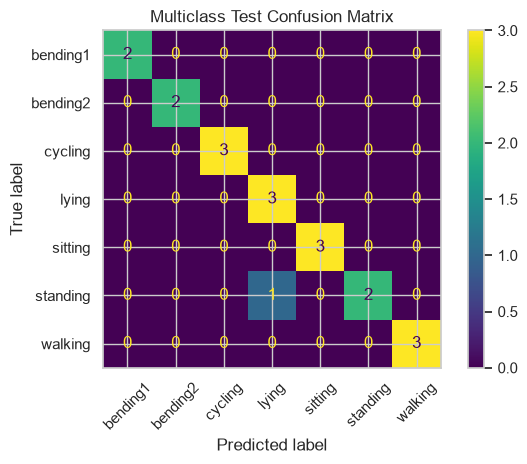

In [35]:
X_test_multi, y_test_multi, _ = (
    make_multiclass_dataset(
        best_multi_l,
        test_keys
    )
)

pred_multi = (
    multiclass_l1_model.predict(
        X_test_multi
    )
)

prob_multi = (
    multiclass_l1_model.predict_proba(
        X_test_multi
    )
)

multi_test_accuracy = accuracy_score(
    y_test_multi,
    pred_multi
)

multi_test_error = (
    1 - multi_test_accuracy
)

print(
    "Multiclass test accuracy:",
    multi_test_accuracy
)

print(
    "Multiclass test error:",
    multi_test_error
)

print("\nClassification Report:")

print(
    classification_report(
        y_test_multi,
        pred_multi
    )
)


ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    pred_multi,
    xticks_rotation=45
)

plt.title(
    "Multiclass Test Confusion Matrix"
)

plt.tight_layout()
plt.show()

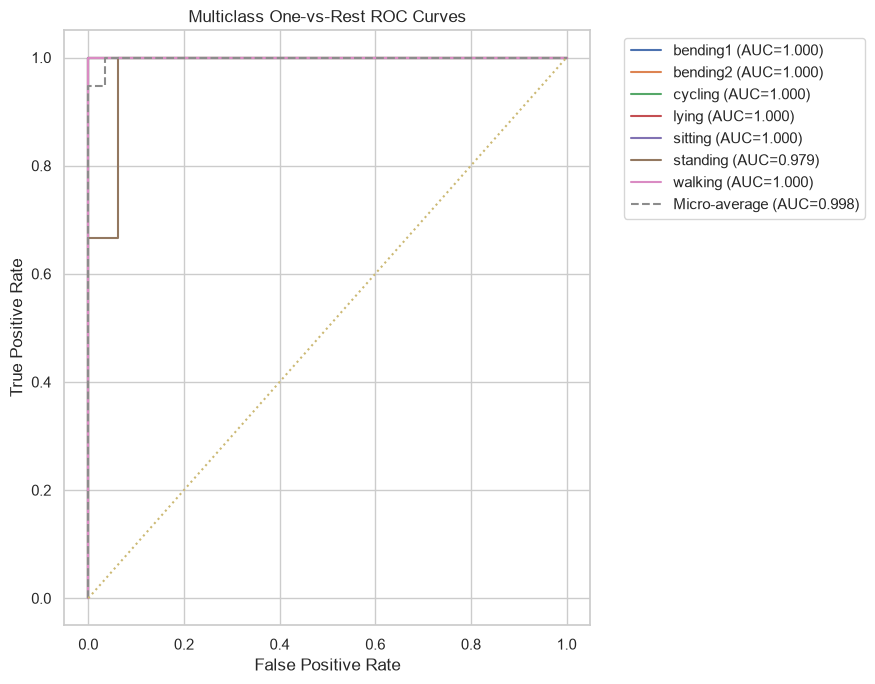

,Class,AUC
0,bending1,1.000000
1,bending2,1.000000
2,cycling,1.000000
3,lying,1.000000
4,sitting,1.000000
5,standing,0.979167
6,walking,1.000000


Micro-average AUC: 0.9981532779316713


In [36]:
multi_classes = (
    multiclass_l1_model
    .named_steps["logit"]
    .classes_
)

y_test_multi_binary = label_binarize(
    y_test_multi,
    classes=multi_classes
)

multiclass_auc_records = []

plt.figure(figsize=(9, 7))

for i, class_name in enumerate(
    multi_classes
):

    fpr_i, tpr_i, _ = roc_curve(
        y_test_multi_binary[:, i],
        prob_multi[:, i]
    )

    auc_i = auc(
        fpr_i,
        tpr_i
    )

    multiclass_auc_records.append({
        "Class": class_name,
        "AUC": auc_i
    })

    plt.plot(
        fpr_i,
        tpr_i,
        label=(
            f"{class_name} "
            f"(AUC={auc_i:.3f})"
        )
    )


micro_fpr, micro_tpr, _ = roc_curve(
    y_test_multi_binary.ravel(),
    prob_multi.ravel()
)

micro_auc = auc(
    micro_fpr,
    micro_tpr
)

plt.plot(
    micro_fpr,
    micro_tpr,
    linestyle="--",
    label=(
        f"Micro-average "
        f"(AUC={micro_auc:.3f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Multiclass One-vs-Rest ROC Curves"
)

plt.legend(
    bbox_to_anchor=(
        1.05,
        1
    ),
    loc="upper left"
)

plt.grid(True)
plt.tight_layout()
plt.show()


multiclass_auc_table = pd.DataFrame(
    multiclass_auc_records
)

display(
    multiclass_auc_table
)

print(
    "Micro-average AUC:",
    micro_auc
)

### 2(c)i — Multiclass ROC and AUC Interpretation

The multiclass ROC analysis was performed using a **one-vs-rest**
approach. For each activity class, that class was treated as the
positive class and all remaining activity classes were treated as
the negative class.

The class-specific AUC values are:

| Class | AUC |
|---|---:|
| bending1 | 1.0000 |
| bending2 | 1.0000 |
| cycling | 1.0000 |
| lying | 1.0000 |
| sitting | 1.0000 |
| standing | 0.9792 |
| walking | 1.0000 |

The **micro-average AUC is approximately 0.9982**.

These results indicate that the L1-penalized multinomial logistic
regression model has excellent discriminative ability across the
seven activity classes.

Six of the seven classes achieve an AUC of 1.0, meaning that their
predicted probabilities perfectly rank observations of that class
above observations belonging to the other classes in this test set.

The `standing` class has a slightly lower AUC of approximately
0.9792. Although this is still very high, it suggests that standing
is somewhat harder to distinguish from the remaining activity
classes than the other categories.

The micro-average ROC curve also shows near-perfect overall
performance, with an AUC of approximately 0.9982. Since the
micro-average aggregates decisions across all classes, this result
indicates very strong overall discrimination.

It is important to note that an AUC of 1.0 does not necessarily mean
that every observation is classified correctly at the final decision
threshold. ROC-AUC measures ranking performance across all possible
thresholds, whereas the final multiclass prediction is based on the
class with the largest predicted probability.

Overall, the ROC results indicate that the L1-penalized multinomial
logistic regression model separates the seven activity classes very
effectively, with only slightly weaker discrimination for the
`standing` class.


### 2(c)ii Naive Bayes Classification

Repeat the multiclass classification using:

1. Gaussian Naive Bayes
2. Multinomial Naive Bayes

For each classifier, select the best number of segments \(l\)
using stratified cross-validation.

In [37]:
gaussian_records = []

for l in range(1, 21):

    X_l, y_l, _ = (
        make_multiclass_dataset(
            l,
            train_keys
        )
    )

    gaussian_pipeline = Pipeline([
        (
            "scale",
            StandardScaler()
        ),
        (
            "nb",
            GaussianNB()
        )
    ])

    scores = cross_val_score(
        gaussian_pipeline,
        X_l,
        y_l,
        cv=multiclass_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    gaussian_records.append({
        "l": l,
        "cv_accuracy": scores.mean()
    })


gaussian_results = pd.DataFrame(
    gaussian_records
)

display(
    gaussian_results
)

best_gaussian_row = (
    gaussian_results
    .sort_values(
        [
            "cv_accuracy",
            "l"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)

best_gaussian_l = int(
    best_gaussian_row["l"]
)

best_gaussian_cv = float(
    best_gaussian_row[
        "cv_accuracy"
    ]
)

print(
    "Best Gaussian NB l:",
    best_gaussian_l
)

print(
    "Best Gaussian CV accuracy:",
    best_gaussian_cv
)

,l,cv_accuracy
0,1,0.870098
1,2,0.898693
2,3,0.710784
3,4,0.767157
4,5,0.710784
5,6,0.694444
6,7,0.666667
7,8,0.680556
8,9,0.667484
9,10,0.651144


Best Gaussian NB l: 2
Best Gaussian CV accuracy: 0.8986928104575163


Gaussian NB Test Accuracy: 0.8421052631578947
Gaussian NB Test Error: 0.1578947368421053


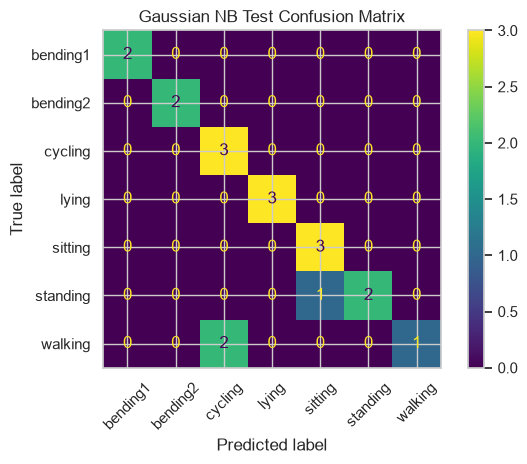

In [38]:
X_train_gnb, y_train_gnb, _ = (
    make_multiclass_dataset(
        best_gaussian_l,
        train_keys
    )
)

X_test_gnb, y_test_gnb, _ = (
    make_multiclass_dataset(
        best_gaussian_l,
        test_keys
    )
)

gaussian_model = Pipeline([
    (
        "scale",
        StandardScaler()
    ),
    (
        "nb",
        GaussianNB()
    )
])

gaussian_model.fit(
    X_train_gnb,
    y_train_gnb
)

pred_gnb = gaussian_model.predict(
    X_test_gnb
)

prob_gnb = gaussian_model.predict_proba(
    X_test_gnb
)

gaussian_test_accuracy = accuracy_score(
    y_test_gnb,
    pred_gnb
)

gaussian_test_error = (
    1 - gaussian_test_accuracy
)

print(
    "Gaussian NB Test Accuracy:",
    gaussian_test_accuracy
)

print(
    "Gaussian NB Test Error:",
    gaussian_test_error
)

ConfusionMatrixDisplay.from_predictions(
    y_test_gnb,
    pred_gnb,
    xticks_rotation=45
)

plt.title(
    "Gaussian NB Test Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [39]:
multinomial_records = []

for l in range(1, 21):

    X_l, y_l, _ = (
        make_multiclass_dataset(
            l,
            train_keys
        )
    )

    multinomial_pipeline = Pipeline([
        (
            "scale",
            MinMaxScaler()
        ),
        (
            "nb",
            MultinomialNB()
        )
    ])

    scores = cross_val_score(
        multinomial_pipeline,
        X_l,
        y_l,
        cv=multiclass_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    multinomial_records.append({
        "l": l,
        "cv_accuracy": scores.mean()
    })


multinomial_results = pd.DataFrame(
    multinomial_records
)

display(
    multinomial_results
)

best_multinomial_row = (
    multinomial_results
    .sort_values(
        [
            "cv_accuracy",
            "l"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)

best_multinomial_l = int(
    best_multinomial_row["l"]
)

best_multinomial_cv = float(
    best_multinomial_row[
        "cv_accuracy"
    ]
)

print(
    "Best Multinomial NB l:",
    best_multinomial_l
)

print(
    "Best Multinomial CV accuracy:",
    best_multinomial_cv
)

,l,cv_accuracy
0,1,0.753268
1,2,0.695261
2,3,0.666667
3,4,0.696078
4,5,0.753268
5,6,0.695261
6,7,0.680556
7,8,0.680556
8,9,0.666667
9,10,0.739379


Best Multinomial NB l: 1
Best Multinomial CV accuracy: 0.7532679738562091


Multinomial NB Test Accuracy: 0.6842105263157895
Multinomial NB Test Error: 0.3157894736842105


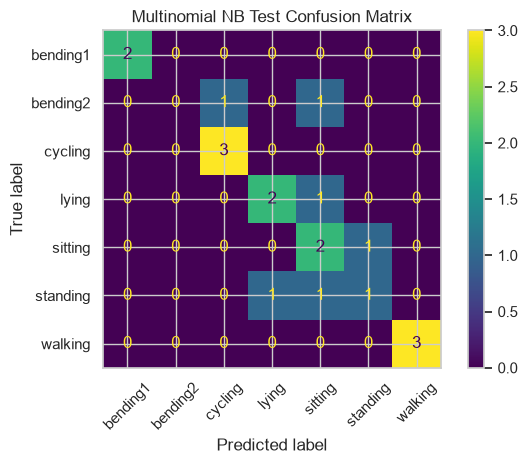

In [40]:
X_train_mnb, y_train_mnb, _ = (
    make_multiclass_dataset(
        best_multinomial_l,
        train_keys
    )
)

X_test_mnb, y_test_mnb, _ = (
    make_multiclass_dataset(
        best_multinomial_l,
        test_keys
    )
)

multinomial_model = Pipeline([
    (
        "scale",
        MinMaxScaler()
    ),
    (
        "nb",
        MultinomialNB()
    )
])

multinomial_model.fit(
    X_train_mnb,
    y_train_mnb
)

pred_mnb = multinomial_model.predict(
    X_test_mnb
)

prob_mnb = multinomial_model.predict_proba(
    X_test_mnb
)

multinomial_test_accuracy = accuracy_score(
    y_test_mnb,
    pred_mnb
)

multinomial_test_error = (
    1 - multinomial_test_accuracy
)

print(
    "Multinomial NB Test Accuracy:",
    multinomial_test_accuracy
)

print(
    "Multinomial NB Test Error:",
    multinomial_test_error
)


ConfusionMatrixDisplay.from_predictions(
    y_test_mnb,
    pred_mnb,
    xticks_rotation=45
)

plt.title(
    "Multinomial NB Test Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [41]:
def multiclass_macro_auc(
    model,
    X_test,
    y_test
):

    classes = (
        model
        .named_steps[
            list(
                model.named_steps.keys()
            )[-1]
        ]
        .classes_
    )

    probabilities = (
        model.predict_proba(
            X_test
        )
    )

    y_binary = label_binarize(
        y_test,
        classes=classes
    )

    return roc_auc_score(
        y_binary,
        probabilities,
        average="macro",
        multi_class="ovr"
    )


gaussian_macro_auc = (
    multiclass_macro_auc(
        gaussian_model,
        X_test_gnb,
        y_test_gnb
    )
)

multinomial_macro_auc = (
    multiclass_macro_auc(
        multinomial_model,
        X_test_mnb,
        y_test_mnb
    )
)

print(
    "Gaussian NB Macro AUC:",
    gaussian_macro_auc
)

print(
    "Multinomial NB Macro AUC:",
    multinomial_macro_auc
)

Gaussian NB Macro AUC: 1.0
Multinomial NB Macro AUC: 0.9285714285714286


### 2(c)iii Comparison of Multiclass Methods

In [42]:
multiclass_comparison = pd.DataFrame({
    "Method": [
        "L1 Multinomial Logistic Regression",
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],

    "Best l": [
        best_multi_l,
        best_gaussian_l,
        best_multinomial_l
    ],

    "CV Accuracy": [
        best_multi_cv_accuracy,
        best_gaussian_cv,
        best_multinomial_cv
    ],

    "Test Error": [
        multi_test_error,
        gaussian_test_error,
        multinomial_test_error
    ]
})

display(
    multiclass_comparison
    .sort_values(
        "Test Error"
    )
)

,Method,Best l,CV Accuracy,Test Error
0,L1 Multinomial Logistic Regression,1,0.855392,0.052632
1,Gaussian Naive Bayes,2,0.898693,0.157895
2,Multinomial Naive Bayes,1,0.753268,0.315789


### 2(c)iii — Comparison of Multiclass Classification Methods

The three multiclass classification methods were compared using
cross-validation accuracy and test error.

| Method | Best \(l\) | CV Accuracy | Test Error |
|---|---:|---:|---:|
| L1 Multinomial Logistic Regression | 1 | 0.8554 | 0.0526 |
| Gaussian Naive Bayes | 2 | 0.8987 | 0.1579 |
| Multinomial Naive Bayes | 1 | 0.7533 | 0.3158 |

The **Gaussian Naive Bayes** model achieved the highest
cross-validation accuracy, approximately **89.87%**.

However, the **L1-penalized multinomial logistic regression**
achieved the lowest test error, approximately **5.26%**, compared
with **15.79%** for Gaussian Naive Bayes and **31.58%** for
Multinomial Naive Bayes.

Therefore, based on performance on the held-out test set, the
**L1-penalized multinomial logistic regression performs best** in
this experiment.

The difference between cross-validation and test performance is also
noteworthy. Although Gaussian Naive Bayes had the best
cross-validation accuracy, it generalized less effectively to the
test set than the L1 multinomial logistic regression model.

Multinomial Naive Bayes performed worst among the three methods.
This is reasonable because Multinomial Naive Bayes is most naturally
suited to non-negative count-like data, while the time-domain features
in this problem are continuous measurements. Even after scaling the
features to non-negative values, its distributional assumptions may
not match the data well.

Gaussian Naive Bayes is more suitable for continuous features, but it
assumes conditional independence among predictors within each class.
The extracted time-domain features are likely to be correlated, so
this assumption may limit its predictive performance.

L1-penalized multinomial logistic regression is more flexible in this
setting because it directly models class probabilities and uses L1
regularization to reduce the influence of unnecessary features.

### Conclusion

Among the three methods, **L1-penalized multinomial logistic
regression is the preferred multiclass classifier for this dataset**
because it achieves the smallest test error.

Gaussian Naive Bayes provides competitive cross-validation
performance but a larger test error, while Multinomial Naive Bayes
performs substantially worse on the held-out test data.

## 3. ISLR 4.8.3

For QDA with one predictor, suppose that an observation from class \(k\) satisfies

\[
X \mid Y=k \sim N(\mu_k,\sigma_k^2).
\]

Let \(\pi_k\) denote the prior probability that an observation belongs to class \(k\).

The class-conditional density is

\[
f_k(x)
=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left[
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right].
\]

By Bayes' rule, the Bayes classifier assigns an observation \(x\) to the class that maximizes

\[
P(Y=k\mid X=x)
\propto
\pi_k f_k(x).
\]

Therefore, we can equivalently maximize the logarithm:

\[
\delta_k(x)
=
\log \pi_k
+
\log f_k(x).
\]

Substituting the normal density gives

\[
\delta_k(x)
=
\log \pi_k
-\log \sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
-\frac{1}{2}\log(2\pi).
\]

The last term is the same for every class and therefore can be ignored. Hence,

\[
\delta_k(x)
=
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
-\log \sigma_k
+\log \pi_k.
\]

Expanding the squared term,

\[
(x-\mu_k)^2
=
x^2-2\mu_kx+\mu_k^2,
\]

so

\[
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+
\frac{\mu_k}{\sigma_k^2}x
-
\frac{\mu_k^2}{2\sigma_k^2}
-
\log \sigma_k
+
\log \pi_k.
\]

Thus, the discriminant function has the form

\[
\delta_k(x)
=
a_kx^2+b_kx+c_k,
\]

where

\[
a_k=-\frac{1}{2\sigma_k^2}.
\]

Therefore, each class-specific discriminant function is **quadratic in \(x\)**.

To find the decision boundary between classes \(k\) and \(l\), we set

\[
\delta_k(x)=\delta_l(x).
\]

This gives

\[
\left(
\frac{1}{2\sigma_l^2}
-
\frac{1}{2\sigma_k^2}
\right)x^2
+
\left(
\frac{\mu_k}{\sigma_k^2}
-
\frac{\mu_l}{\sigma_l^2}
\right)x
+
C
=
0,
\]

where \(C\) contains the terms that do not depend on \(x\).

If the class variances are different,

\[
\sigma_k^2 \neq \sigma_l^2,
\]

the coefficient of \(x^2\) is nonzero. Therefore, the decision boundary is determined by a **quadratic equation**, not a linear one.

This is the key difference between QDA and LDA. In LDA, all classes are assumed to have the same variance:

\[
\sigma_1^2=\sigma_2^2=\cdots=\sigma_K^2.
\]

In that case, the \(x^2\) terms are identical across classes and cancel when discriminant functions are compared, leaving a linear decision boundary.

In QDA, the class-specific variances are allowed to differ, so the quadratic terms generally do not cancel.

### Conclusion

The Bayes classifier for QDA is generally **not linear** because the class-specific variances produce class-specific coefficients for \(x^2\).

Therefore, the Bayes decision boundary is **quadratic**.


## 4. ISLR 4.8.7

We want to calculate the probability that a company will issue a dividend given that its percentage profit last year was

\[
X=4.
\]

Let

\[
Y=\text{Yes}
\]

denote that the company issues a dividend, and

\[
Y=\text{No}
\]

denote that it does not.

We are given:

\[
\mu_{\text{Yes}}=10,
\]

\[
\mu_{\text{No}}=0,
\]

and the common variance is

\[
\sigma^2=36.
\]

Therefore,

\[
\sigma=6.
\]

The prior probabilities are

\[
P(Y=\text{Yes})=0.8
\]

and

\[
P(Y=\text{No})=0.2.
\]

Using Bayes' theorem,

\[
P(Y=\text{Yes}\mid X=4)
=
\frac{
P(X=4\mid Y=\text{Yes})P(Y=\text{Yes})
}{
P(X=4)
}.
\]

Since there are only two classes,

\[
P(Y=\text{Yes}\mid X=4)
=
\frac{
0.8f_{\text{Yes}}(4)
}{
0.8f_{\text{Yes}}(4)
+
0.2f_{\text{No}}(4)
}.
\]

For a normal random variable,

\[
f(x)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp
\left(
-\frac{(x-\mu)^2}{2\sigma^2}
\right).
\]

Because both classes have the same variance, the common factor

\[
\frac{1}{\sqrt{2\pi\sigma^2}}
\]

cancels from the numerator and denominator.

For companies that issue dividends,

\[
f_{\text{Yes}}(4)
\propto
\exp
\left(
-\frac{(4-10)^2}{2(36)}
\right)
=
\exp(-0.5).
\]

For companies that do not issue dividends,

\[
f_{\text{No}}(4)
\propto
\exp
\left(
-\frac{(4-0)^2}{2(36)}
\right)
=
\exp\left(-\frac{2}{9}\right).
\]

Therefore,

\[
P(Y=\text{Yes}\mid X=4)
=
\frac{
0.8e^{-0.5}
}{
0.8e^{-0.5}
+
0.2e^{-2/9}
}.
\]

Using

\[
e^{-0.5}\approx0.6065
\]

and

\[
e^{-2/9}\approx0.8007,
\]

we obtain

\[
P(Y=\text{Yes}\mid X=4)
=
\frac{
0.8(0.6065)
}{
0.8(0.6065)+0.2(0.8007)
}
\approx 0.752.
\]

### Conclusion

The estimated probability that the company will issue a dividend is approximately

\[
\boxed{0.752}
\]

or about

\[
\boxed{75.2\%}.
\]

Therefore, based on the given information, the company would be more likely to issue a dividend than not.